# Etapa 6. Filtrado probabilístico (Bloom Filter y Count-Min Sketch)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de la etapa 6: Aris.

## Función de la etapa en el pipeline

El escenario B pide **reconocer medios de pago, dispositivos o cuentas señaladas y estimar la intensidad de intentos dentro de una ventana temporal, verificando las alertas antes de bloquear operaciones**. La etapa 6 recibe los eventos en el orden de servicio de la etapa 2 y revisa cada compra y cada alerta de pago con dos estructuras probabilísticas implementadas a mano.

| Pregunta | Estructura | Respuesta | Error posible |
| --- | --- | --- | --- |
| ¿Esta cuenta, tarjeta o dispositivo está señalado? | **Bloom Filter** (Bloom, 1970) | "posiblemente sí" o "seguro que no" | Falsos positivos, nunca falsos negativos |
| ¿Cuántos intentos de pago hizo esta tarjeta en la ventana? | **Count-Min Sketch** (Cormode y Muthukrishnan, 2005) | Una estimación f̂ ≥ f | Sobreestima a lo más ε·N con probabilidad 1 − δ |

Como las dos estructuras pueden equivocarse por exceso, **toda alerta se verifica con una estructura exacta antes de actuar**. El positivo del Bloom Filter se confirma en la lista exacta (la `TablaHash` de la etapa 3) y la ráfaga del CMS se confirma con el conteo exacto de las órdenes de la ventana. La estructura exacta solo se consulta para los pocos eventos que el filtro probabilístico marca.

**Salidas para las etapas siguientes.** `ordenes_bloqueadas.json` (la etapa 8 excluye esas órdenes del grafo de co-compra) y `alertas.jsonl` (la etapa 9 las muestra en el panel de alertas), en `data/interim/<CATEGORIA>/etapa_6/`.

**Cómo se ejecuta.** El paso 5 recorre los 9.9 millones de eventos con `ejecutar_etapa` de `src/etapa_6/probabilistic.py` y deja sus resultados en `data/interim/<CATEGORIA>/etapa_6/`. Este notebook muestra las estructuras, hace una demostración en vivo con los primeros eventos del stream y analiza los resultados de la corrida completa. Los experimentos de escalabilidad de 1K a 10M están en el paso 8.

## Paso 1. Configuración y entrada

| Archivo | Origen | Uso |
| --- | --- | --- |
| `etapa2_eventos.jsonl` | Etapa 2 | Stream de eventos limpios en orden de servicio, leído línea por línea |
| `listas_senalados.json` | Etapa 0 (generador) | 30 cuentas, 200 tarjetas y 50 dispositivos señalados, de los que el detector conoce la mitad |
| `etapa0_inyecciones.json` | Etapa 0 (generador) | Verdad de referencia con las ráfagas y compras fraudulentas inyectadas |

**Lista conocida y verdad de referencia.** La etapa 0 usa las claves de `listas_senalados.json` en todas sus ráfagas de fraude: cada ráfaga elige al azar una cuenta, una tarjeta y un dispositivo de esas listas. Si el detector conociera las listas completas, detectaría todo el fraude por construcción y la evaluación no mediría nada. Por eso el detector conoce solo la mitad de cada lista (`FRACCION_CONOCIDA = 0.5`), elegida con la semilla. La otra mitad representa defraudadores que todavía no están en la lista. Una ráfaga escapa del Bloom Filter solo si su cuenta, su tarjeta y su dispositivo son nuevos. Como los tres se eligen por separado, eso ocurre en promedio en 1 de cada 8 ráfagas, y para ellas solo queda la regla de intensidad del Count-Min Sketch. La evaluación del paso 5 usa las listas completas como verdad de referencia: un evento es fraude si su cuenta está en la lista de cuentas de la etapa 0, porque solo las ráfagas usan esas cuentas.

La salida de la etapa se guarda en `data/interim/<CATEGORIA>/etapa_6/` y las gráficas en `results/etapa_6/`. La celda muestra al final la plataforma y la semilla, que el enunciado pide reportar junto con los tiempos.

In [1]:
import json
import platform
import sys
import time
from collections import Counter
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.etapa_3.storage import RUTA_EVENTOS_ETAPA2, leer_eventos
from src.etapa_6.probabilistic import (CARPETA_ETAPA6, EPSILON, DELTA, FRACCION_CONOCIDA, N_VENTANAS, P_FP,
                                       RUTA_ALERTAS, RUTA_BLOQUEADAS, UMBRAL, VENTANA_S, BloomFilter,
                                       CountMinSketch, DetectorFraude, cargar_listas, dividir_listas)

CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_6"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
CARPETA_ETAPA6.mkdir(parents=True, exist_ok=True)
RUTA_METRICAS = CARPETA_ETAPA6 / "metricas.json"
RUTA_COMPRAS = CARPETA_ETAPA6 / "compras.npz"

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor() or platform.machine(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": config.SEED,
}

listas = cargar_listas()                                                    # verdad de referencia
conocidas, nuevas = dividir_listas(listas, FRACCION_CONOCIDA, config.SEED)   # lo que conoce el detector
inyecciones = json.loads((CARPETA_INTERIM / "etapa0_inyecciones.json").read_text(encoding="utf-8"))
print(f"Categoría: {config.CATEGORIA}   semilla: {config.SEED}")
print("Señaladas por la etapa 0:  ", {k: len(v) for k, v in listas.items()})
print("Conocidas por el detector: ", {k: len(v) for k, v in conocidas.items()})
print("Fraude inyectado por la etapa 0:",
      {k: inyecciones[k] for k in ["rafagas_fraude", "compras_fraudulentas", "tipo_payment_alert", "alertas_legitimas"]})
PLATAFORMA

Categoría: Office_Products   semilla: 42
Señaladas por la etapa 0:   {'cuentas': 30, 'tarjetas': 200, 'dispositivos': 50}
Conocidas por el detector:  {'cuentas': 15, 'tarjetas': 100, 'dispositivos': 25}
Fraude inyectado por la etapa 0: {'rafagas_fraude': 2970, 'compras_fraudulentas': 37095, 'tipo_payment_alert': 15184, 'alertas_legitimas': 3958}


{'sistema': 'Windows-10-10.0.19045-SP0',
 'procesador': 'AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD',
 'nucleos': 8,
 'ram_gb': 32.1,
 'python': '3.12.0',
 'semilla': 42}

## Paso 2. Bloom Filter

Un Bloom Filter es un arreglo de **m bits** y **k funciones hash**. Insertar una clave enciende sus k bits; consultar revisa si los k están encendidos. Si alguno está apagado, la clave **seguro** no se insertó. Si todos están encendidos, **posiblemente** se insertó, porque otros elementos pudieron encender esos bits (falso positivo). Nunca hay falsos negativos, porque los bits de una clave insertada no se apagan.

Con n claves y una tasa objetivo p, los valores óptimos son

$$m = -\frac{n \ln p}{(\ln 2)^2}, \qquad k = \frac{m}{n}\ln 2, \qquad p_{FP} \approx \left(1 - e^{-kn/m}\right)^k$$

La fórmula de p_FP sale de que, después de insertar n claves, un bit sigue apagado con probabilidad (1 − 1/m)^(kn) ≈ e^(−kn/m), y una clave que no se insertó da positivo si sus k bits están encendidos. El k óptimo deja encendida la mitad de los bits. Con p = 0.01 resultan 9.6 bits por clave y k = 7, sin importar el largo de la clave (Broder y Mitzenmacher, 2004).

Los m bits se guardan en un `bytearray`, y el bit p está en el byte p // 8, en la posición p % 8. Las k posiciones de una clave son k valores independientes de 64 bits tomados de un único BLAKE2b de la clave, reducidos módulo m. Así se calcula un solo hash por clave, y es determinista entre ejecuciones, a diferencia del `hash()` de Python. La alternativa habitual es el **doble hashing**, g_i(x) = h1(x) + i·h2(x) mod m, que solo necesita dos valores de hash (Kirsch y Mitzenmacher, 2006). Su tasa de falsos positivos converge a la de k hashes independientes cuando m crece, pero en un filtro chico como el de la etapa queda por encima; la comparación de más abajo lo mide. Cada clave lleva su tipo como prefijo (`tarjeta:pay_…`) para que una cuenta y una tarjeta con el mismo texto no se confundan.

### Complejidad

| Operación | Tiempo | Espacio |
| --- | --- | --- |
| Insertar | O(k) | — |
| Consultar | O(k) | — |
| Estructura | — | m = O(n·log(1/p)) bits, sin importar el largo de las claves |

Una tabla hash exacta, como un `set` o la `TablaHash` de la etapa 3, responde sin errores en O(1) esperado, pero guarda cada clave completa: O(n) entradas con la clave, su hash y una referencia.

### Casos de uso, límites y compromisos

- **Casos de uso.** Sirve para descartar rápido las consultas cuya respuesta casi siempre es "no", antes de una consulta exacta más cara. Por ejemplo, las listas negras de URL o de tarjetas, y las bases de datos con árboles LSM, como Bigtable (Chang et al., 2006), Cassandra o RocksDB, que consultan un Bloom Filter por archivo antes de leerlo del disco.
- **Límites.** No se pueden eliminar claves, porque apagar un bit puede borrar otras claves; el *counting Bloom filter* lo resuelve con contadores en lugar de bits (Fan et al., 2000). No permite listar las claves insertadas. El tamaño se fija para un n previsto, y si se insertan más claves la tasa de falsos positivos crece.
- **Compromiso.** Cada factor 10 menos en p cuesta 4.8 bits más por clave, porque m/n = log₂(1/p) / ln 2. Un falso positivo cuesta una consulta exacta de más, y un falso negativo no puede ocurrir. Por eso en la etapa todo positivo se verifica en la `TablaHash` exacta de la etapa 3 antes de bloquear, como pide el enunciado.

### El Bloom Filter de la etapa

Se construye con las 140 claves que conoce el detector. Además de la tasa teórica, la celda compara la tasa medida con la tasa esperada para este filtro, (fracción de bits encendidos)^k. Una clave ausente da positivo cuando sus k posiciones caen en bits encendidos, así que ese valor corrige la diferencia entre los bits que encendió este filtro y el promedio que supone la fórmula. La tasa medida se reporta con su intervalo de confianza de 95 %. También se comprueba que ninguna clave insertada dé negativo, y se cuentan las claves señaladas que el detector no conoce y que dan positivo. Esas son falsos positivos respecto de la lista conocida, y la verificación exacta las descarta.

In [2]:
from src.etapa_6.probabilistic import claves_senaladas

claves = claves_senaladas(conocidas)                 # solo las claves que conoce el detector
bloom = BloomFilter.para(len(claves), P_FP)
for c in claves:
    bloom.agregar(c)

print(f"n = {len(claves)} claves, p objetivo = {P_FP}")
print(f"m = {bloom.m:,} bits ({bloom.memoria_bytes} bytes), k = {bloom.k} funciones hash, "
      f"{bloom.bits_encendidos() / bloom.m:.1%} de bits encendidos")
print(f"Tasa de falsos positivos teórica: {bloom.tasa_fp_teorica():.4f}")

tarjeta = "tarjeta:" + conocidas["tarjetas"][0]
print(f"\n¿{tarjeta} está señalada?  {tarjeta in bloom}")
print(f"Posiciones de sus {bloom.k} bits: {bloom._posiciones(tarjeta)}")
ausentes = [f"tarjeta:pay_{i:08x}" for i in range(100_000)]
fp = sum(c in bloom for c in ausentes)
print(f"De 100 000 tarjetas no señaladas, {fp:,} dan positivo ({fp / len(ausentes):.4f}): son falsos positivos")

tasa = fp / len(ausentes)
margen = 1.96 * np.sqrt(tasa * (1 - tasa) / len(ausentes))
print(f"Intervalo de 95 % de la tasa medida: {tasa - margen:.4f} a {tasa + margen:.4f}. Tasa esperada para "
      f"este filtro, (bits encendidos)^k: {(bloom.bits_encendidos() / bloom.m) ** bloom.k:.4f}")
claves_nuevas = claves_senaladas(nuevas)
print(f"Falsos negativos entre las {len(claves)} claves insertadas: {sum(c not in bloom for c in claves)}")
print(f"Claves señaladas que el detector no conoce y dan positivo: {sum(c in bloom for c in claves_nuevas)} "
      f"de {len(claves_nuevas)}")

n = 140 claves, p objetivo = 0.01
m = 1,342 bits (168 bytes), k = 7 funciones hash, 52.1% de bits encendidos
Tasa de falsos positivos teórica: 0.0100

¿tarjeta:pay_bf2c14a0 está señalada?  True
Posiciones de sus 7 bits: [124, 592, 709, 1194, 865, 798, 105]
De 100 000 tarjetas no señaladas, 1,060 dan positivo (0.0106): son falsos positivos
Intervalo de 95 % de la tasa medida: 0.0100 a 0.0112. Tasa esperada para este filtro, (bits encendidos)^k: 0.0104
Falsos negativos entre las 140 claves insertadas: 0
Claves señaladas que el detector no conoce y dan positivo: 2 de 140


### Doble hashing frente a hashes independientes

El doble hashing es la forma habitual de obtener las k posiciones con solo dos hashes. Para filtros del tamaño del de la etapa, la celda construye 200 filtros con cada forma de calcular las posiciones, con 140 claves distintas en cada uno, y mide la tasa de falsos positivos con 10 000 claves ausentes por filtro. Se reporta la media de las 200 tasas con su error estándar.

In [3]:
from src.etapa_6.probabilistic import hashes_base


class BloomDobleHashing(BloomFilter):
    """Bloom Filter con las k posiciones por doble hashing: g_i(x) = h1(x) + i·h2(x) mod m."""

    def _posiciones(self, clave):
        h1, h2 = hashes_base(clave)
        return [(h1 + i * h2) % self.m for i in range(self.k)]


N_FILTROS, N_CONSULTAS = 200, 10_000
filas = []
for nombre, clase in [("doble hashing", BloomDobleHashing), ("hashes independientes (la etapa)", BloomFilter)]:
    medidas, esperadas = [], []
    for f in range(N_FILTROS):
        filtro = clase.para(len(claves), P_FP)
        for j in range(len(claves)):
            filtro.agregar(f"tarjeta:filtro{f}_clave{j}")
        esperadas.append((filtro.bits_encendidos() / filtro.m) ** filtro.k)
        medidas.append(sum(f"tarjeta:filtro{f}_ausente{j}" in filtro for j in range(N_CONSULTAS)) / N_CONSULTAS)
    filas.append({"posiciones": nombre, "tasa medida (media)": np.mean(medidas),
                  "error estándar": np.std(medidas, ddof=1) / np.sqrt(N_FILTROS),
                  "tasa esperada, (bits encendidos)^k": np.mean(esperadas), "tasa teórica": filtro.tasa_fp_teorica()})
print(f"{N_FILTROS} filtros de {len(claves)} claves (m = {filtro.m:,} bits, k = {filtro.k}) por forma de calcular "
      f"las posiciones, {N_CONSULTAS:,} claves ausentes por filtro")
pd.DataFrame(filas).set_index("posiciones").round(5)

200 filtros de 140 claves (m = 1,342 bits, k = 7) por forma de calcular las posiciones, 10,000 claves ausentes por filtro


,tasa medida (media),error estándar,"tasa esperada, (bits encendidos)^k",tasa teórica
posiciones,,,,
doble hashing,0.01091,0.00011,0.01002,0.01004
hashes independientes (la etapa),0.01017,0.00010,0.01004,0.01004


## Paso 3. Count-Min Sketch por ventanas

El CMS es una matriz de **d filas × w contadores**. Cada fila tiene su propia función hash. Agregar una clave suma 1 en un contador de cada fila; estimar devuelve el **mínimo** de esos d contadores. Como varias claves pueden caer en el mismo contador, cada contador es mayor o igual que la frecuencia real, y por eso **el CMS nunca subestima**. Con

$$w = \left\lceil \frac{e}{\varepsilon} \right\rceil, \qquad d = \left\lceil \ln \frac{1}{\delta} \right\rceil$$

la estimación cumple f ≤ f̂ ≤ f + ε·N con probabilidad 1 − δ, donde N es el total de la ventana. La memoria es w·d contadores, **independiente del número de claves distintas**.

**Por qué se cumple la cota.** En cada fila, el contador de una clave x suma su frecuencia f(x) más la de las otras claves que caen en el mismo contador. Si la función hash de la fila reparte las claves de forma uniforme e independiente, ese exceso vale en promedio a lo más N/w ≤ ε·N/e. Por la desigualdad de Markov, el exceso supera ε·N con probabilidad a lo más 1/e en cada fila. Como las d filas usan hashes independientes, el mínimo supera ε·N solo si lo superan las d filas, lo que ocurre con probabilidad a lo más e^(−d) ≤ δ (Cormode y Muthukrishnan, 2005).

**Funcionamiento interno.** Cada fila es un `array('q')` de w contadores de 64 bits. Las d posiciones de una clave, una por fila, salen de la misma función `posiciones` del Bloom Filter, es decir, de un único BLAKE2b. La cota supone filas independientes. Con doble hashing, dos claves con el mismo par (h1 mod w, h2 mod w) chocan en las d filas a la vez, con una probabilidad del orden de 1/w² en lugar de 1/w^d; la comparación de más abajo lo mide. `CMSVentana` guarda un sketch por ventana fija de 5 minutos en un arreglo circular de 288 posiciones, y la estimación de una tarjeta suma su ventana y la anterior.

### Complejidad

| Operación | Tiempo | Espacio |
| --- | --- | --- |
| Agregar | O(d) | — |
| Estimar | O(d) | — |
| Estructura | — | w·d = O((1/ε)·ln(1/δ)) contadores, sin importar cuántas claves distintas ni cuántos eventos haya |

Un diccionario exacto (`dict` o `Counter`) responde sin error en O(1) esperado, pero guarda una entrada por cada clave distinta.

### Casos de uso, límites y compromisos

- **Casos de uso.** Contar frecuencias en un stream con memoria fija, por ejemplo las consultas más frecuentes, el tráfico por dirección IP en una red o, en esta etapa, los intentos de pago por tarjeta. Combinado con un heap de candidatos, da los elementos más frecuentes (*heavy hitters*) (Cormode y Muthukrishnan, 2005). RedisBloom (`CMS.*`) y Apache Spark (`CountMinSketch`) lo ofrecen.
- **Límites.** Solo sobreestima, y el error se mide respecto del total N, así que el error relativo de una clave poco frecuente puede ser grande. No permite listar las claves. Con cuentas negativas el mínimo deja de ser una cota válida. La *actualización conservadora* (Estan y Varghese, 2002), que solo incrementa los contadores mínimos, reduce la sobreestimación. El Count Sketch (Charikar, Chen y Farach-Colton, 2002) da estimaciones sin sesgo, con error en los dos sentidos.
- **Compromiso.** La memoria crece como 1/ε, así que reducir el error a la mitad duplica w. Cada fila más reduce δ en un factor e. En esta etapa el CMS solo decide qué tarjetas se verifican con el conteo exacto, así que una sobreestimación cuesta una verificación de más y nunca oculta una ráfaga.

El enunciado pide definir la clave, la ventana y el umbral.

| Parámetro | Valor | Justificación |
| --- | --- | --- |
| Clave | `payment_id` de cada **intento de pago** (una orden) | Una orden con 4 productos genera un solo pago. Contar productos retenía compras legítimas de varias unidades |
| Ventana | Fijas de 5 min; la estimación suma la ventana actual y la anterior | Una ráfaga del generador son 5 a 20 compras separadas por 5 a 40 s (de 25 s a 13 min). Sumar dos ventanas evita que una ráfaga quede partida en el borde |
| Umbral | 5 intentos en la ventana | Mínimo tamaño de una ráfaga inyectada; el Paso 6 lo justifica con los datos |
| ε, δ | 0.01 y 0.01 → w = 272, d = 5 | En una ventana hay decenas de órdenes, así que ε·N < 1 y el CMS es casi exacto con 11 KB por ventana |
| Ventanas retenidas | 288 (24 h) en un arreglo circular | La etapa 2 entrega en orden de prioridad y no de ts. Durante el incidente de la etapa 2 hay eventos que se atienden horas después |

### El CMS de una ventana

La celda siguiente construye el CMS de una ventana con los parámetros de la etapa y le agrega 2 000 tarjetas con un intento cada una y una tarjeta con 7. Comprueba que ninguna estimación queda por debajo de la frecuencia real y cuenta las tarjetas cuyo error supera la cota ε·N, que según la garantía deben ser a lo más una fracción δ = 1 %.

In [4]:
cms = CountMinSketch.para(EPSILON, DELTA)
print(f"ε = {EPSILON}, δ = {DELTA}  ->  w = {cms.w}, d = {cms.d}, {cms.memoria_bytes / 1024:.1f} KB por ventana")
print(f"Ventanas de {VENTANA_S // 60} min, {N_VENTANAS} retenidas: {N_VENTANAS * cms.memoria_bytes / 1e6:.1f} MB en total")

# Ejemplo: una tarjeta con 7 intentos entre 2 000 tarjetas con 1 intento cada una
for i in range(2_000):
    cms.agregar(f"pay_{i:08x}")
for _ in range(7):
    cms.agregar("pay_rafaga")
print(f"\nEstimación de pay_rafaga: {cms.estimar('pay_rafaga')} (real 7)")
estimaciones = [cms.estimar(f"pay_{i:08x}") for i in range(2_000)]
print(f"Tarjetas con 1 intento: estimación media {np.mean(estimaciones):.3f}, máxima {max(estimaciones)} "
      f"(cota ε·N = {cms.epsilon * cms.total:.1f})")
errores = np.array(estimaciones) - 1
print(f"Subestimaciones: {int((errores < 0).sum())}; tarjetas con un error mayor que ε·N: "
      f"{(errores > cms.epsilon * cms.total).mean():.2%} (δ = {DELTA:.0%})")

ε = 0.01, δ = 0.01  ->  w = 272, d = 5, 10.6 KB por ventana
Ventanas de 5 min, 288 retenidas: 3.1 MB en total

Estimación de pay_rafaga: 12 (real 7)
Tarjetas con 1 intento: estimación media 5.378, máxima 10 (cota ε·N = 20.1)
Subestimaciones: 0; tarjetas con un error mayor que ε·N: 0.00% (δ = 1%)


### Doble hashing frente a hashes independientes en el CMS

Con doble hashing, dos claves que comparten el par (h1 mod w, h2 mod w) chocan en las d filas. Como h2 es impar y w = 272 es par, h2 mod w solo toma 136 valores, así que eso ocurre con probabilidad 1/(272·136) ≈ 2.7·10⁻⁵ por par. Con filas independientes, la probabilidad de chocar en las d filas es 1/w^d. La celda simula 10 000 ventanas de 20 tarjetas con un intento cada una, del orden del volumen de dos ventanas del stream, y cuenta las tarjetas cuya estimación supera su frecuencia real con cada forma de calcular las posiciones.

In [5]:
from src.etapa_6.probabilistic import hashes_base


class CMSDobleHashing(CountMinSketch):
    """Count-Min Sketch con la posición de la fila i por doble hashing: h1(x) + i·h2(x) mod w."""

    def agregar(self, clave, cuenta=1):
        h1, h2 = hashes_base(clave)
        for i, fila in enumerate(self.filas):
            fila[(h1 + i * h2) % self.w] += cuenta
        self.total += cuenta

    def estimar(self, clave):
        h1, h2 = hashes_base(clave)
        return min(fila[(h1 + i * h2) % self.w] for i, fila in enumerate(self.filas))


N_SIMULADAS, TARJETAS_POR_VENTANA = 10_000, 20
filas = []
for nombre, clase in [("doble hashing", CMSDobleHashing), ("hashes independientes (la etapa)", CountMinSketch)]:
    sobreestimadas = 0
    for v in range(N_SIMULADAS):
        sketch = clase.para(EPSILON, DELTA)
        tarjetas = [f"pay_v{v}_t{t}" for t in range(TARJETAS_POR_VENTANA)]
        for t in tarjetas:
            sketch.agregar(t)
        sobreestimadas += sum(sketch.estimar(t) > 1 for t in tarjetas)
    total = N_SIMULADAS * TARJETAS_POR_VENTANA
    filas.append({"posiciones": nombre, "tarjetas sobreestimadas": sobreestimadas, "tarjetas": total,
                  "fracción": sobreestimadas / total})
pd.DataFrame(filas).set_index("posiciones")

,tarjetas sobreestimadas,tarjetas,fracción
posiciones,,,
doble hashing,92,200000,0.000460
hashes independientes (la etapa),1,200000,0.000005


## Paso 4. Demostración en vivo con los primeros eventos del stream

El `DetectorFraude` combina las dos estructuras. Para cada compra o alerta de pago:

1. Consulta la cuenta, la tarjeta y el dispositivo en el Bloom Filter. Un positivo se confirma en la lista exacta; si se confirma, la operación se **bloquea**. Si no, es un falso positivo del filtro y no tiene efecto.
2. Si es una compra, suma el intento de pago al CMS de su ventana. Si la estimación llega al umbral, cuenta exactamente las órdenes de esa tarjeta en la ventana. Si el conteo exacto también llega al umbral, la orden queda **retenida para revisión**. Una ráfaga sin clave señalada indica un patrón sospechoso, pero no basta para probar el fraude.

El detector se construye con la lista conocida del paso 1: las 15 cuentas, 100 tarjetas y 25 dispositivos conocidos se insertan en el Bloom Filter y en la `TablaHash` exacta. Una compra de una ráfaga cuyas tres claves son nuevas no da positivo en el Bloom Filter, y solo la regla de intensidad puede retenerla.

Aquí se procesan los primeros 300 000 eventos de la salida de la etapa 2.

In [6]:
detector = DetectorFraude(conocidas)                 # solo la lista conocida
alertas = []
t0 = time.perf_counter()
for e in islice(leer_eventos(RUTA_EVENTOS_ETAPA2), 300_000):
    alerta = detector.procesar(e)
    if alerta is not None:
        alertas.append(alerta)
duracion = time.perf_counter() - t0

print(f"300 000 eventos en {duracion:.1f} s; {detector.metricas['revisados']:,} compras y alertas de pago revisadas")
print(dict(detector.metricas))
pd.DataFrame(alertas)[["event_type", "user_id", "payment_id", "motivos", "estimado_cms", "conteo_exacto",
                       "decision"]].drop_duplicates("payment_id").head(10)

300 000 eventos en 3.3 s; 62,614 compras y alertas de pago revisadas
{'revisados': 62614, 'bloom_consultas': 187842, 'intentos': 42219, 'bloom_positivos': 3956, 'bloom_falsos_positivos': 1896, 'alertas': 1374, 'bloquear': 1230, 'alertas_cuenta': 701, 'cms_alertas': 776, 'alertas_rafaga': 776, 'alertas_dispositivo': 162, 'revisar': 144, 'alertas_tarjeta': 367}


,event_type,user_id,payment_id,motivos,estimado_cms,conteo_exacto,decision
0,purchase,APOFB6P2MCUBESJ7DYTZHQOO37JT,pay_b1aa0f6a,[cuenta],1.0,NaN,bloquear
10,payment_alert,ARNGLYUYGR5OWD7THFRRC75OD2PW,pay_1986b4b2,[dispositivo],NaN,NaN,bloquear
28,purchase,AK4WIA6CXPYWUPZCHWJSPQNXKWII,pay_fb140bc3,[cuenta],1.0,NaN,bloquear
49,purchase,AE4PQHBWG6HFLMH7ABL5NLWND5UA,pay_771f406e,[rafaga],5.0,5.0,revisar
51,purchase,AEVBRR5DORGEPBVHN6HNTN3CLVRA,pay_5a2e3971,[rafaga],5.0,5.0,revisar
55,payment_alert,AR6D7F6IDNXKTQMSIWA5RXXVLCVK,pay_e32f2e63,[tarjeta],NaN,NaN,bloquear
75,purchase,ANXRTHHNAKVMFOETAMSAUEOBMGKY,pay_1327f1bc,[tarjeta],1.0,NaN,bloquear
83,purchase,APCYYEPRI3NGRXGJ7UOQDHKSHHCU,pay_f6478986,[dispositivo],1.0,NaN,bloquear
91,payment_alert,AICJIKREHWWCNRNGN4SW3YMALY36,pay_dbfdd97e,[cuenta],NaN,NaN,bloquear
98,payment_alert,A26DAJV6MWCWUDY3TD7ZLNLQK32D,pay_bea4ff31,[tarjeta],NaN,NaN,bloquear


## Paso 5. Resultados sobre el stream completo

La función `ejecutar_etapa` recorre los 9 940 617 eventos de la etapa 2 con el detector del paso 4 y escribe las salidas de la etapa. Para evaluar se usa la verdad de referencia del generador, según la cual un evento es fraude si su cuenta pertenece a la lista completa de cuentas fraudulentas de la etapa 0. El detector solo conoce la mitad de las listas, así que la evaluación separa el fraude con alguna clave conocida, que el Bloom Filter puede reconocer, del fraude con sus tres claves nuevas, que solo la regla de ráfaga puede retener. Las listas completas, el conteo exacto por (tarjeta, ventana) y las claves distintas consultadas se usan solo para evaluar; el detector no los consulta.

La celda siguiente la ejecuta. Tarda unos minutos, porque lee y decodifica los 3.6 GB del archivo de la etapa 2. La celda posterior muestra las decisiones, primero con todo el fraude junto y después separado en esos dos grupos.

In [7]:
from src.etapa_6.probabilistic import ejecutar_etapa

t0 = time.perf_counter()
metricas = ejecutar_etapa(conocidas, listas, RUTA_EVENTOS_ETAPA2, RUTA_ALERTAS, RUTA_BLOQUEADAS, RUTA_METRICAS,
                          RUTA_COMPRAS)
print(f"Etapa 6 sobre el stream completo: {time.perf_counter() - t0:.0f} s")

2,000,000 eventos (36 s)
4,000,000 eventos (73 s)
6,000,000 eventos (109 s)
8,000,000 eventos (145 s)
Etapa 6 sobre el stream completo: 184 s


In [8]:
metricas = json.loads(RUTA_METRICAS.read_text(encoding="utf-8"))
d, ev = metricas["detector"], metricas["evaluacion"]
print(f"Eventos: {metricas['eventos']:,}   compras y alertas revisadas: {d['revisados']:,}   "
      f"intentos de pago: {d['intentos']:,}")
print(f"Tiempo del detector: {metricas['tiempo_detector_s']:.0f} s "
      f"({metricas['us_por_evento_revisado']:.1f} µs por evento revisado)")

decisiones = pd.DataFrame({
    "fraude real": [ev.get("bloquear_fraude", 0), ev.get("revisar_fraude", 0), ev.get("aprobar_fraude", 0)],
    "legítimo": [ev.get("bloquear_legitimo", 0), ev.get("revisar_legitimo", 0), ev.get("aprobar_legitimo", 0)],
}, index=["bloquear", "revisar", "aprobar"])
display(decisiones)
print(f"Bloqueos: precisión {metricas['precision_bloqueos']:.4f}, recall {metricas['recall_bloqueos']:.4f}")
print(f"Todas las alertas (bloquear + revisar): precisión {metricas['precision_alertas']:.4f}, "
      f"recall {metricas['recall_alertas']:.4f}")
print(f"Órdenes bloqueadas para la etapa 8: {metricas['ordenes_bloqueadas']:,}")

grupos = {"fraude con alguna clave conocida": "fraude_conocido", "fraude con sus tres claves nuevas": "fraude_nuevo",
          "legítimo": "legitimo"}
por_grupo = pd.DataFrame({nombre: {decision: ev.get(f"{decision}_{grupo}", 0) for decision in ["bloquear", "revisar", "aprobar"]}
                          for nombre, grupo in grupos.items()})
display(por_grupo)
for nombre in list(grupos)[:2]:
    total = por_grupo[nombre].sum()
    print(f"{nombre}: {total:,} operaciones; bloqueadas {por_grupo.at['bloquear', nombre] / total:.1%}, "
          f"retenidas {por_grupo.at['revisar', nombre] / total:.1%}, aprobadas {por_grupo.at['aprobar', nombre] / total:.1%}")

Eventos: 9,940,617   compras y alertas revisadas: 1,993,954   intentos de pago: 1,336,626
Tiempo del detector: 56 s (28.1 µs por evento revisado)


,fraude real,legítimo
bloquear,41532,0
revisar,3247,2931
aprobar,2987,1943257


Bloqueos: precisión 1.0000, recall 0.8695
Todas las alertas (bloquear + revisar): precisión 0.9386, recall 0.9375
Órdenes bloqueadas para la etapa 8: 31,994


,fraude con alguna clave conocida,fraude con sus tres claves nuevas,legítimo
bloquear,41532,0,0
revisar,0,3247,2931
aprobar,0,2987,1943257


fraude con alguna clave conocida: 41,532 operaciones; bloqueadas 100.0%, retenidas 0.0%, aprobadas 0.0%
fraude con sus tres claves nuevas: 6,234 operaciones; bloqueadas 0.0%, retenidas 52.1%, aprobadas 47.9%


### Bloom Filter en el stream real

Cada evento revisado consulta hasta tres claves. Los positivos que la lista exacta no confirma son falsos positivos del filtro. La tasa medida se compara con la teórica. La tasa de un Bloom Filter se define por clave, y en el stream cada clave se consulta muchas veces, una por cada compra o alerta de esa cuenta, tarjeta o dispositivo. Una clave que da falso positivo lo da en todas sus consultas, así que la celda calcula también la tasa sobre las claves distintas no conocidas, que es la que corresponde comparar con la teórica.

In [9]:
positivos_reales = d["bloom_positivos"] - d["bloom_falsos_positivos"]
negativos = d["bloom_consultas"] - positivos_reales if "bloom_consultas" in d else 3 * d["revisados"] - positivos_reales
print(f"Consultas al Bloom Filter: {negativos + positivos_reales:,}")
print(f"Positivos confirmados por la lista exacta: {positivos_reales:,}")
print(f"Falsos positivos (descartados por la verificación): {d['bloom_falsos_positivos']:,} "
      f"-> tasa {d['bloom_falsos_positivos'] / negativos:.4f} (teórica {metricas['bloom']['tasa_fp_teorica']:.4f})")
print(f"Sin la verificación exacta, cada uno de esos {d['bloom_falsos_positivos']:,} positivos habría bloqueado una operación legítima.")
print(f"Memoria: Bloom Filter {metricas['memoria_bloom_bytes']} bytes "
      f"(m = {metricas['bloom']['m']:,} bits, k = {metricas['bloom']['k']})")

distintas, fp_distintas = metricas["bloom_claves_no_conocidas"], metricas["bloom_falsos_positivos_distintos"]
tasa_distintas = fp_distintas / distintas
margen = 1.96 * np.sqrt(tasa_distintas * (1 - tasa_distintas) / distintas)
print(f"Claves distintas no conocidas consultadas: {distintas:,}; dan positivo: {fp_distintas:,}")
print(f"Tasa por clave distinta: {tasa_distintas:.4f} (intervalo de 95 %: {tasa_distintas - margen:.4f} a "
      f"{tasa_distintas + margen:.4f}); teórica {metricas['bloom']['tasa_fp_teorica']:.4f}")
print(f"Tasa por consulta: {d['bloom_falsos_positivos'] / negativos:.4f}, con {negativos / distintas:.2f} consultas "
      f"por clave distinta en promedio")

Consultas al Bloom Filter: 5,981,862
Positivos confirmados por la lista exacta: 70,860
Falsos positivos (descartados por la verificación): 61,183 -> tasa 0.0104 (teórica 0.0100)
Sin la verificación exacta, cada uno de esos 61,183 positivos habría bloqueado una operación legítima.
Memoria: Bloom Filter 168 bytes (m = 1,342 bits, k = 7)
Claves distintas no conocidas consultadas: 3,162,462; dan positivo: 33,116
Tasa por clave distinta: 0.0105 (intervalo de 95 %: 0.0104 a 0.0106); teórica 0.0100
Tasa por consulta: 0.0104, con 1.87 consultas por clave distinta en promedio


### Count-Min Sketch frente al conteo exacto en el stream real

Para cada compra se guardó la estimación del CMS y el conteo exacto de órdenes de su tarjeta en las mismas dos ventanas (un diccionario `(tarjeta, ventana) -> órdenes` usado solo como línea base).

In [10]:
compras = np.load(RUTA_COMPRAS)
estimado, conteo, fraude = compras["estimado"], compras["conteo"], compras["fraude"]
error = estimado.astype(np.int64) - conteo
print(f"Compras: {len(error):,}   subestimaciones: {(error < 0).sum()}   con error > 0: {(error > 0).sum():,} "
      f"({(error > 0).mean():.4%})   error máximo: {error.max()}")
print(f"Eventos descartados por llegar más de 24 h tarde: {metricas['cms_descartados_por_tardios']:,}")
pares = metricas["pares_tarjeta_ventana_exactos"]
print(f"Memoria: CMS {metricas['memoria_cms_bytes'] / 1e6:.1f} MB fijos (288 ventanas) frente a "
      f"{pares:,} pares (tarjeta, ventana) en el diccionario exacto")

Compras: 1,978,936   subestimaciones: 0   con error > 0: 1,627 (0.0822%)   error máximo: 2
Eventos descartados por llegar más de 24 h tarde: 0
Memoria: CMS 3.1 MB fijos (288 ventanas) frente a 1,260,275 pares (tarjeta, ventana) en el diccionario exacto


## Paso 6. Elección del umbral

La regla de ráfaga se evalúa sola, sin la lista de señalados, para cada umbral posible. Así se mide qué aportaría el CMS frente a un atacante cuya tarjeta todavía no está en la lista. Una compra cuenta como alerta si el conteo de órdenes de su tarjeta en la ventana llega al umbral. La tabla agrega el recall sobre las compras fraudulentas con sus tres claves nuevas, que son las que en el pipeline solo esta regla puede retener.

**Justificación del umbral.** Con umbral 5, la regla detecta 24 780 compras fraudulentas, el 67.6 %, con precisión 0.895, y retiene 2 903 compras legítimas. El recall sigue casi exactamente la fracción de compras que llegan después de las primeras u − 1 de su ráfaga. Las ráfagas del generador tienen de 5 a 20 compras, 12.5 en promedio, y con u = 5 esa fracción es (12.5 − 4) / 12.5 = 68 %. Por eso ningún umbral útil llega a un recall de 1. Bajar a 4 sube el recall 8.1 puntos, a 75.7 %, pero multiplica por 2.5 las compras legítimas retenidas, que pasan a 7 305. Subir a 6 reduce a la mitad las legítimas retenidas, a 1 484, pero pierde 8.1 puntos de recall. Se elige 5, el tamaño mínimo de una ráfaga. Cinco compras seguidas, separadas por 5 a 40 s, caben en las dos ventanas que suma la estimación, así que toda ráfaga que llega completa a la etapa alcanza el umbral en su quinta compra. El recall sobre el fraude con sus tres claves nuevas es casi igual al total, 67.8 % con umbral 5, porque la regla no depende de las claves. Es el recall que obtiene la etapa sobre las compras que el Bloom Filter no puede reconocer.

,alertas,fraude detectado,legítimas retenidas,precisión,recall,recall en fraude con claves nuevas
umbral,,,,,,
2,159124,33690,125434,0.212,0.919,0.919
3,54125,30722,23403,0.568,0.838,0.839
4,35057,27752,7305,0.792,0.757,0.758
5,27683,24780,2903,0.895,0.676,0.678
6,23301,21817,1484,0.936,0.595,0.598
7,19916,19044,872,0.956,0.519,0.523
8,17042,16460,582,0.966,0.449,0.452
9,14442,14053,389,0.973,0.383,0.386
10,12115,11850,265,0.978,0.323,0.326


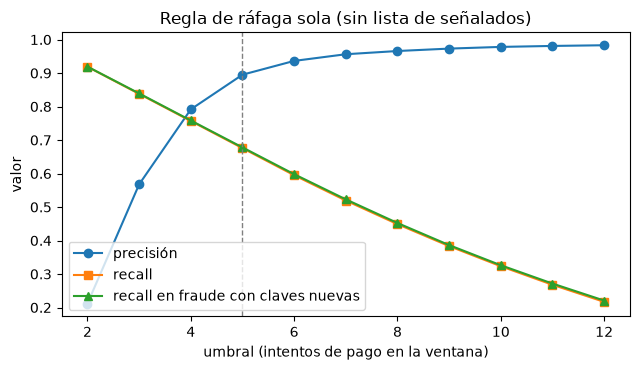

In [11]:
nueva = fraude & ~compras["conocida"]                # compras fraudulentas con sus tres claves nuevas
filas = []
for u in range(2, 13):
    alerta = conteo >= u
    vp, fp_ = int((alerta & fraude).sum()), int((alerta & ~fraude).sum())
    filas.append({"umbral": u, "alertas": int(alerta.sum()), "fraude detectado": vp, "legítimas retenidas": fp_,
                  "precisión": vp / max(1, vp + fp_), "recall": vp / max(1, fraude.sum()),
                  "recall en fraude con claves nuevas": int((alerta & nueva).sum()) / max(1, nueva.sum())})
umbrales = pd.DataFrame(filas).set_index("umbral")
display(umbrales.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(umbrales.index, umbrales["precisión"], marker="o", label="precisión")
ax.plot(umbrales.index, umbrales["recall"], marker="s", label="recall")
ax.plot(umbrales.index, umbrales["recall en fraude con claves nuevas"], marker="^",
        label="recall en fraude con claves nuevas")
ax.axvline(UMBRAL, color="gray", ls="--", lw=1)
ax.set_xlabel("umbral (intentos de pago en la ventana)")
ax.set_ylabel("valor")
ax.set_title("Regla de ráfaga sola (sin lista de señalados)")
ax.legend()
fig.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "umbral.png", dpi=150)
plt.show()

## Paso 7. Salida de la etapa 6

Los archivos quedan en `data/interim/<CATEGORIA>/etapa_6/`.

| Archivo | Contenido | Lo usa |
| --- | --- | --- |
| `alertas.jsonl` | Una línea por operación con alerta: motivos, estimación del CMS, conteo exacto y decisión | Etapa 9 (panel de alertas, uso previsto) |
| `ordenes_bloqueadas.json` | `order_id` de las operaciones bloqueadas | Etapa 8 (se excluyen del grafo de co-compra, uso previsto) |
| `metricas.json` | Conteos, tiempos, memoria y evaluación | Informe |
| `compras.npz` | Por compra, la estimación del CMS, el conteo exacto, si es fraude y si tiene alguna clave conocida | Pasos 5 y 6 de este notebook |

In [12]:
bloqueadas = json.loads(RUTA_BLOQUEADAS.read_text(encoding="utf-8"))
n_alertas = sum(1 for _ in open(RUTA_ALERTAS, encoding="utf-8"))
print(f"{RUTA_ALERTAS.name}: {n_alertas:,} alertas ({RUTA_ALERTAS.stat().st_size / 1e6:.1f} MB)")
print(f"{RUTA_BLOQUEADAS.name}: {len(bloqueadas):,} órdenes bloqueadas")
with open(RUTA_ALERTAS, encoding="utf-8") as f:
    ejemplo = [json.loads(linea) for linea in islice(f, 3)]
pd.DataFrame(ejemplo)

alertas.jsonl: 47,710 alertas (17.5 MB)
ordenes_bloqueadas.json: 31,994 órdenes bloqueadas


,event_id,event_type,ts,user_id,order_id,payment_id,device_id,motivos,clave_senalada,estimado_cms,conteo_exacto,decision,fraude_real
0,e000001899,purchase,1.656702e+09,APOFB6P2MCUBESJ7DYTZHQOO37JT,o00000292,pay_b1aa0f6a,dev_1712fb16,[cuenta],cuenta:APOFB6P2MCUBESJ7DYTZHQOO37JT,1.0,None,bloquear,True
1,e000001904,payment_alert,1.656702e+09,APOFB6P2MCUBESJ7DYTZHQOO37JT,o00000296,pay_b1aa0f6a,dev_1712fb16,[cuenta],cuenta:APOFB6P2MCUBESJ7DYTZHQOO37JT,NaN,None,bloquear,True
2,e000001902,purchase,1.656702e+09,APOFB6P2MCUBESJ7DYTZHQOO37JT,o00000295,pay_b1aa0f6a,dev_1712fb16,[cuenta],cuenta:APOFB6P2MCUBESJ7DYTZHQOO37JT,2.0,None,bloquear,True


## Paso 8. Experimentos: Bloom Filter frente a set y Count-Min Sketch frente a dict

El enunciado pide comparar las estructuras probabilísticas con una alternativa exacta en **tiempo, memoria, falsos positivos y error de frecuencia**, con tamaños de 1K a 10M y gráficos log-log.

Las mediciones las hace la celda siguiente y quedan en `results/etapa_6/`, con el procesador y la versión de Python con que se midieron. Si los archivos existen se reutilizan; para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

| Experimento | Estructura | Alternativa exacta | Datos |
| --- | --- | --- | --- |
| Pertenencia | `BloomFilter` con p = 0.01 | `set` de Python | n claves distintas con forma de tarjeta; 100 000 claves ausentes para medir falsos positivos |
| Frecuencia | `CountMinSketch` con ε = 0.01 y δ = 0.01, los del pipeline | `dict` de Python | n eventos sobre n/10 claves con frecuencias Zipf (a = 1.2) |
| Compromiso memoria-error | CMS con ε de 0.1 a 0.0001 | `Counter` | 1M eventos Zipf |

**Repeticiones.** Las consultas se miden en bloques de 10 000 claves, con 100 repeticiones en todos los tamaños, incluido 10M. La construcción, que inserta las n claves, se repite 100 veces hasta 100K, 20 veces con 1M y una vez con 10M, porque cada construcción del Bloom Filter o del CMS en Python cuesta algunos microsegundos por clave y 100 repeticiones con 1M o 10M tomarían varios minutos u horas por estructura. La celda imprime el tiempo de una repetición y cuánto tardarían 100. El recolector de basura se desactiva durante cada medición, y la estructura medida se libera fuera del intervalo medido. La memoria se mide en una pasada aparte con `tracemalloc`, sin medir tiempo, porque el rastreo de memoria hace más lenta cada asignación.

In [13]:
import gc
import statistics
import tracemalloc

# Las mediciones guardadas en results/etapa_6/ se reutilizan. Con True se miden de nuevo.
REEJECUTAR_EXPERIMENTOS = False
R = CARPETA_RESULTADOS
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 100, 1_000_000: 20, 10_000_000: 1}   # construcciones
REPETICIONES_CONSULTA = 100    # bloques de consultas, en todos los tamaños
N_BLOQUE = 10_000              # consultas por bloque
N_CONSULTAS = 100_000          # claves ausentes para medir la tasa de falsos positivos
EPSILON_EXP, DELTA_EXP = EPSILON, DELTA      # los del pipeline
ZIPF_A = 1.2                   # sesgo del stream del CMS: pocas claves muy frecuentes


def resultados(ruta, medir_tabla):
    """Lee la tabla de resultados si existe. Si no, la mide con medir_tabla() y la guarda con la plataforma."""
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        print(f"Resultados leídos de {ruta.name}")
        return pd.read_csv(ruta, dtype={"procesador": str, "python": str})
    tabla = medir_tabla().assign(procesador=PLATAFORMA["procesador"], python=PLATAFORMA["python"])
    tabla.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta.name}")
    return tabla


def plataforma_de(tabla):
    """Procesador y versión de Python con que se midió una tabla de resultados."""
    return f"{tabla['procesador'].iloc[0]}, Python {tabla['python'].iloc[0]}"


def claves_unicas(n, prefijo, semilla):
    """n claves distintas con forma de identificador de tarjeta."""
    valores = np.random.default_rng(semilla).choice(2 ** 62, size=n, replace=False)
    return [f"{prefijo}_{v:016x}" for v in valores.tolist()]


def flujo_zipf(n, semilla):
    """n eventos sobre un universo de n/10 claves con frecuencias tipo Zipf."""
    universo = max(100, n // 10)
    rng = np.random.default_rng(semilla)
    rangos = rng.zipf(ZIPF_A, size=n)
    rangos = np.where(rangos > universo, rng.integers(1, universo + 1, size=n), rangos)
    return [f"pay_{r:09d}" for r in rangos.tolist()]


def tamano_claves(claves):
    return sum(sys.getsizeof(c) for c in claves)


def medir(funcion, repeticiones):
    """Tiempos en segundos de `repeticiones` ejecuciones de funcion(), con el recolector de basura desactivado.

    La estructura que devuelve funcion() se libera fuera del intervalo medido.
    """
    tiempos = []
    for _ in range(repeticiones):
        gc.collect()
        gc.disable()
        try:
            t0 = time.perf_counter()
            resultado = funcion()
            tiempos.append(time.perf_counter() - t0)
        finally:
            gc.enable()
        del resultado
    return tiempos


def medir_bloques(funcion, claves, tam_bloque=N_BLOQUE):
    """Segundos por clave de funcion(bloque) en REPETICIONES_CONSULTA bloques de tam_bloque claves de `claves`."""
    tam = min(tam_bloque, len(claves))
    tiempos = []
    for r in range(REPETICIONES_CONSULTA):
        bloque = [claves[(r * tam + j) % len(claves)] for j in range(tam)]     # en orden circular
        gc.disable()
        try:
            t0 = time.perf_counter()
            resultado = funcion(bloque)
            tiempos.append((time.perf_counter() - t0) / tam)
        finally:
            gc.enable()
        del resultado
    return tiempos


def memoria(funcion):
    """(actual, pico) en bytes de lo que funcion() deja reservado y de lo que reserva como máximo."""
    gc.collect()
    tracemalloc.start()
    resultado = funcion()
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    del resultado
    return actual, pico


# ----- Bloom Filter frente a set ---------------------------------------------------

def experimento_bloom():
    filas = []
    for n in TAMANOS:
        reps = REPETICIONES[n]
        insertadas = claves_unicas(n, "pay", config.SEED + n)
        ausentes = claves_unicas(N_CONSULTAS, "aus", config.SEED + n + 1)
        consultadas = insertadas[:N_CONSULTAS]

        def construir_bloom():
            bloom = BloomFilter.para(n, P_FP)
            for c in insertadas:
                bloom.agregar(c)
            return bloom

        def construir_set():
            s = set()
            for c in insertadas:
                s.add(c)
            return s

        bloom, exacto = construir_bloom(), construir_set()
        t_bloom = medir(construir_bloom, reps)
        t_set = medir(construir_set, reps)
        t_bloom_q = medir_bloques(lambda bloque: [c in bloom for c in bloque], ausentes)
        t_set_q = medir_bloques(lambda bloque: [c in exacto for c in bloque], ausentes)
        falsos_negativos = sum(c not in bloom for c in consultadas)
        falsos_positivos = sum(c in bloom for c in ausentes)
        mem_bloom, pico_bloom = memoria(construir_bloom)
        mem_set, pico_set = memoria(construir_set)

        filas.append({"n": n, "repeticiones": reps, "repeticiones_consulta": REPETICIONES_CONSULTA,
                      "m_bits": bloom.m, "k": bloom.k,
                      "insercion_bloom_us": statistics.mean(t_bloom) / n * 1e6,
                      "insercion_bloom_std_us": (statistics.stdev(t_bloom) if reps > 1 else 0) / n * 1e6,
                      "insercion_set_us": statistics.mean(t_set) / n * 1e6,
                      "insercion_set_std_us": (statistics.stdev(t_set) if reps > 1 else 0) / n * 1e6,
                      "consulta_bloom_us": statistics.mean(t_bloom_q) * 1e6,
                      "consulta_bloom_std_us": statistics.stdev(t_bloom_q) * 1e6,
                      "consulta_set_us": statistics.mean(t_set_q) * 1e6,
                      "consulta_set_std_us": statistics.stdev(t_set_q) * 1e6,
                      "memoria_bloom_bytes": mem_bloom, "pico_bloom_bytes": pico_bloom,
                      "memoria_set_bytes": mem_set, "pico_set_bytes": pico_set,
                      "memoria_claves_bytes": tamano_claves(insertadas),
                      "falsos_negativos": falsos_negativos,
                      "tasa_fp_medida": falsos_positivos / N_CONSULTAS,
                      "tasa_fp_teorica": bloom.tasa_fp_teorica()})
        print(f"Bloom Filter y set, n = {n:,} medido")
        del bloom, exacto, insertadas, ausentes, consultadas
    return pd.DataFrame(filas)


# ----- Count-Min Sketch frente a dict ----------------------------------------------

def errores_cms(cms, exacto):
    errores = np.array([cms.estimar(c) - f for c, f in exacto.items()], dtype=np.int64)
    top = [c for c, _ in exacto.most_common(10)]
    relativo_top = statistics.mean((cms.estimar(c) - exacto[c]) / exacto[c] for c in top)
    cota = cms.epsilon * cms.total
    return {"error_medio": float(errores.mean()), "error_max": int(errores.max()),
            "subestimaciones": int((errores < 0).sum()), "cota_eps_n": cota,
            "fraccion_sobre_cota": float((errores > cota).mean()), "error_relativo_top10": relativo_top}


def experimento_cms():
    filas = []
    for n in TAMANOS:
        reps = REPETICIONES[n]
        flujo = flujo_zipf(n, config.SEED + n)

        def construir_cms():
            cms = CountMinSketch.para(EPSILON_EXP, DELTA_EXP)
            for c in flujo:
                cms.agregar(c)
            return cms

        def construir_dict():
            exacto = {}
            for c in flujo:
                exacto[c] = exacto.get(c, 0) + 1
            return exacto

        cms, exacto = construir_cms(), Counter(construir_dict())
        t_cms = medir(construir_cms, reps)
        t_dict = medir(construir_dict, reps)
        consultas = list(exacto)[:N_CONSULTAS]
        t_cms_q = medir_bloques(lambda bloque: [cms.estimar(c) for c in bloque], consultas)
        t_dict_q = medir_bloques(lambda bloque: [exacto[c] for c in bloque], consultas)
        mem_cms, pico_cms = memoria(construir_cms)
        mem_dict, pico_dict = memoria(construir_dict)
        claves_distintas = list(exacto)

        filas.append({"n": n, "repeticiones": reps, "repeticiones_consulta": REPETICIONES_CONSULTA,
                      "w": cms.w, "d": cms.d, "claves_distintas": len(exacto),
                      "actualizacion_cms_us": statistics.mean(t_cms) / n * 1e6,
                      "actualizacion_cms_std_us": (statistics.stdev(t_cms) if reps > 1 else 0) / n * 1e6,
                      "actualizacion_dict_us": statistics.mean(t_dict) / n * 1e6,
                      "actualizacion_dict_std_us": (statistics.stdev(t_dict) if reps > 1 else 0) / n * 1e6,
                      "consulta_cms_us": statistics.mean(t_cms_q) * 1e6,
                      "consulta_cms_std_us": statistics.stdev(t_cms_q) * 1e6,
                      "consulta_dict_us": statistics.mean(t_dict_q) * 1e6,
                      "consulta_dict_std_us": statistics.stdev(t_dict_q) * 1e6,
                      "memoria_cms_bytes": mem_cms, "pico_cms_bytes": pico_cms,
                      "memoria_dict_bytes": mem_dict, "pico_dict_bytes": pico_dict,
                      "memoria_claves_bytes": tamano_claves(claves_distintas),
                      **errores_cms(cms, exacto)})
        print(f"CMS y dict, n = {n:,} medido")
        del cms, exacto, flujo, claves_distintas
    return pd.DataFrame(filas)


def experimento_epsilon(n=1_000_000):
    """Compromiso memoria-error: el mismo stream con distintos ε (δ fijo)."""
    flujo = flujo_zipf(n, config.SEED)
    exacto = Counter(flujo)
    filas = []
    for epsilon in [0.1, 0.03, 0.01, 0.003, 0.001, 0.0003, 0.0001]:
        cms = CountMinSketch.para(epsilon, DELTA_EXP)
        for c in flujo:
            cms.agregar(c)
        filas.append({"n": n, "epsilon": epsilon, "w": cms.w, "d": cms.d, "memoria_cms_bytes": cms.memoria_bytes,
                      **errores_cms(cms, exacto)})
    print("Compromiso memoria-error medido")
    return pd.DataFrame(filas)


bloom = resultados(R / "bloom.csv", experimento_bloom)
cms = resultados(R / "cms.csv", experimento_cms)
epsilon = resultados(R / "cms_epsilon.csv", experimento_epsilon)

# Verificación del protocolo y justificación de las construcciones con menos de 100 repeticiones
for tabla in (bloom, cms):
    assert tabla["repeticiones"].tolist() == [REPETICIONES[n] for n in TAMANOS]
    assert (tabla["repeticiones_consulta"] == REPETICIONES_CONSULTA).all()
for nombre, tabla, columna in [("Bloom Filter", bloom, "insercion_bloom_us"), ("CMS", cms, "actualizacion_cms_us")]:
    for _, f in tabla[tabla["repeticiones"] < 100].iterrows():
        segundos = f[columna] * f["n"] / 1e6
        print(f"Construcción del {nombre} con n = {f['n']:,}: {f['repeticiones']} repeticiones de {segundos:.1f} s; "
              f"100 tomarían {100 * segundos / 60:.0f} min")
print(f"Plataforma de las mediciones: {plataforma_de(bloom)}, semilla {config.SEED}")

Resultados leídos de bloom.csv
Resultados leídos de cms.csv
Resultados leídos de cms_epsilon.csv
Construcción del Bloom Filter con n = 1,000,000: 20 repeticiones de 3.8 s; 100 tomarían 6 min
Construcción del Bloom Filter con n = 10,000,000: 1 repeticiones de 38.9 s; 100 tomarían 65 min
Construcción del CMS con n = 1,000,000: 20 repeticiones de 2.7 s; 100 tomarían 5 min
Construcción del CMS con n = 10,000,000: 1 repeticiones de 32.2 s; 100 tomarían 54 min
Plataforma de las mediciones: AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD, Python 3.12.0, semilla 42


### 8.1 Bloom Filter frente a set

#### Tiempo por operación

Insertar y consultar cuestan O(k) en el Bloom Filter y O(1) esperado en el `set`, así que el tiempo **por operación** debería ser constante en n para los dos (pendiente 0 en log-log). El `set` está implementado en C dentro del intérprete; el Bloom Filter está escrito en Python, por eso es más lento en valor absoluto aunque la complejidad sea la misma.

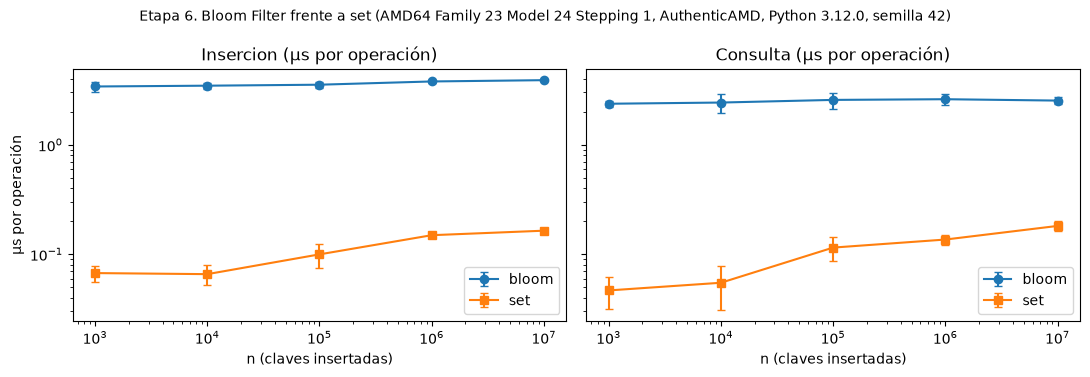

Pendiente log-log del tiempo por operación (esperada ≈ 0): {'insercion bloom': 0.02, 'insercion set': 0.11, 'consulta bloom': 0.01, 'consulta set': 0.16}


,n,repeticiones,repeticiones_consulta,k,insercion_bloom_us,insercion_bloom_std_us,insercion_set_us,consulta_bloom_us,consulta_bloom_std_us,consulta_set_us
0,1000,100,100,7,3.404,0.368,0.067,2.368,0.159,0.047
1,10000,100,100,7,3.462,0.218,0.066,2.429,0.481,0.055
2,100000,100,100,7,3.534,0.243,0.100,2.567,0.431,0.115
3,1000000,20,100,7,3.784,0.106,0.149,2.605,0.277,0.136
4,10000000,1,100,7,3.888,0.000,0.164,2.531,0.186,0.181


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, op in zip(axes, ["insercion", "consulta"]):
    for estructura, marca in [("bloom", "o"), ("set", "s")]:
        ax.errorbar(bloom["n"], bloom[f"{op}_{estructura}_us"], yerr=bloom[f"{op}_{estructura}_std_us"],
                    marker=marca, capsize=3, label=estructura)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n (claves insertadas)"); ax.set_title(f"{op.capitalize()} (µs por operación)")
    ax.legend()
axes[0].set_ylabel("µs por operación")
fig.suptitle(f"Etapa 6. Bloom Filter frente a set ({plataforma_de(bloom)}, semilla {config.SEED})", fontsize=10)
fig.tight_layout(); fig.savefig(R / "bloom_tiempo.png", dpi=150); plt.show()
pendientes = {f"{op} {e}": round(np.polyfit(np.log10(bloom["n"]), np.log10(bloom[f"{op}_{e}_us"]), 1)[0], 2).item()
              for op in ["insercion", "consulta"] for e in ["bloom", "set"]}
print("Pendiente log-log del tiempo por operación (esperada ≈ 0):", pendientes)
bloom[["n", "repeticiones", "repeticiones_consulta", "k", "insercion_bloom_us", "insercion_bloom_std_us",
       "insercion_set_us", "consulta_bloom_us", "consulta_bloom_std_us", "consulta_set_us"]].round(3)

#### Memoria actual y pico

El Bloom Filter ocupa m = −n·ln p / (ln 2)² bits, es decir, **9.6 bits por clave** con p = 0.01, sin importar el largo de la clave. El `set` guarda una referencia y un hash por posición (más el espacio libre de la tabla) y además necesita **las claves mismas**, porque en un servicio real la lista de señalados llega del stream y el `set` debe conservar cada texto. Las dos crecen como O(n), con pendiente 1 en log-log, y la diferencia está en la constante. La memoria actual es la que ocupa la estructura construida, y la pico, el máximo durante la construcción.

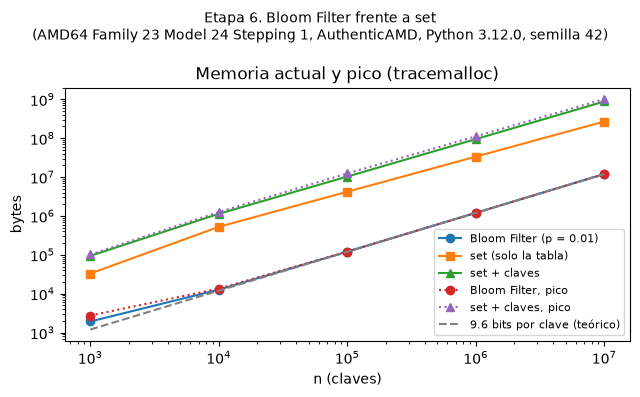

Pendiente log-log de la memoria actual (esperada ≈ 1): {'memoria_bloom_bytes': 0.96, 'set_mas_claves_bytes': 0.99}


,n,memoria_bloom_bytes,pico_bloom_bytes,memoria_set_bytes,pico_set_bytes,set_mas_claves_bytes,bytes_por_clave_bloom,bytes_por_clave_set+claves,veces_menos_memoria
0,1000,1928,2746,32984,41224,93984,1.93,93.98,48.75
1,10000,12711,13529,524504,655624,1134504,1.27,113.45,89.25
2,100000,120543,121361,4194520,6291720,10294520,1.21,102.95,85.40
3,1000000,1200702,1202120,33554648,50331912,94554648,1.20,94.55,78.75
4,10000000,11985404,11986838,268435672,402653448,878435672,1.20,87.84,73.29


In [15]:
bloom["set_mas_claves_bytes"] = bloom["memoria_set_bytes"] + bloom["memoria_claves_bytes"]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(bloom["n"], bloom["memoria_bloom_bytes"], marker="o", label="Bloom Filter (p = 0.01)")
ax.plot(bloom["n"], bloom["memoria_set_bytes"], marker="s", label="set (solo la tabla)")
ax.plot(bloom["n"], bloom["set_mas_claves_bytes"], marker="^", label="set + claves")
ax.plot(bloom["n"], bloom["pico_bloom_bytes"], marker="o", ls=":", label="Bloom Filter, pico")
ax.plot(bloom["n"], bloom["pico_set_bytes"] + bloom["memoria_claves_bytes"], marker="^", ls=":",
        label="set + claves, pico")
ax.plot(bloom["n"], bloom["n"] * 9.585 / 8, ls="--", color="gray", label="9.6 bits por clave (teórico)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n (claves)"); ax.set_ylabel("bytes")
ax.set_title("Memoria actual y pico (tracemalloc)"); ax.legend(fontsize=8)
fig.suptitle(f"Etapa 6. Bloom Filter frente a set\n({plataforma_de(bloom)}, semilla {config.SEED})", fontsize=10)
fig.tight_layout(); fig.savefig(R / "bloom_memoria.png", dpi=150); plt.show()
print("Pendiente log-log de la memoria actual (esperada ≈ 1):",
      {c: round(np.polyfit(np.log10(bloom["n"]), np.log10(bloom[c]), 1)[0], 2).item()
       for c in ["memoria_bloom_bytes", "set_mas_claves_bytes"]})

tabla = bloom[["n", "memoria_bloom_bytes", "pico_bloom_bytes", "memoria_set_bytes", "pico_set_bytes",
               "set_mas_claves_bytes"]].copy()
tabla["bytes_por_clave_bloom"] = tabla["memoria_bloom_bytes"] / tabla["n"]
tabla["bytes_por_clave_set+claves"] = tabla["set_mas_claves_bytes"] / tabla["n"]
tabla["veces_menos_memoria"] = tabla["set_mas_claves_bytes"] / tabla["memoria_bloom_bytes"]
tabla.round(2)

#### Falsos positivos y falsos negativos

Se consultan 100 000 claves que nunca se insertaron. Todas las que dan positivo son falsos positivos. Además se comprueba que ninguna clave insertada da negativo.

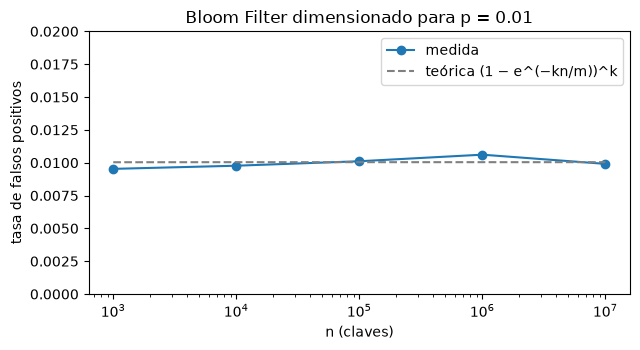

Falsos negativos en todos los tamaños: [0, 0, 0, 0, 0]


,n,m_bits,k,tasa_fp_medida,tasa_fp_teorica
0,1000,9586,7,0.00953,0.010035
1,10000,95851,7,0.00977,0.010039
2,100000,958506,7,0.01011,0.010039
3,1000000,9585059,7,0.01061,0.010039
4,10000000,95850584,7,0.00991,0.010039


In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(bloom["n"], bloom["tasa_fp_medida"], marker="o", label="medida")
ax.plot(bloom["n"], bloom["tasa_fp_teorica"], ls="--", color="gray", label="teórica (1 − e^(−kn/m))^k")
ax.set_xscale("log"); ax.set_ylim(0, 0.02); ax.set_xlabel("n (claves)"); ax.set_ylabel("tasa de falsos positivos")
ax.set_title("Bloom Filter dimensionado para p = 0.01"); ax.legend()
fig.tight_layout(); fig.savefig(R / "bloom_fp.png", dpi=150); plt.show()
print("Falsos negativos en todos los tamaños:", bloom["falsos_negativos"].tolist())
bloom[["n", "m_bits", "k", "tasa_fp_medida", "tasa_fp_teorica"]]

### 8.2 Count-Min Sketch frente a dict

#### Tiempo y memoria

Actualizar y estimar cuestan O(d) en el CMS y O(1) esperado en el `dict`. La memoria del CMS es fija, w·d contadores (con ε = 0.01 y δ = 0.01, los del pipeline, w = 272 y d = 5, es decir, 10 880 bytes de contadores; `tracemalloc` cuenta además el espacio que `array` reserva de más en cada fila, 1/16 de su tamaño, y los encabezados de los objetos), mientras que el `dict` crece con el número de claves distintas.

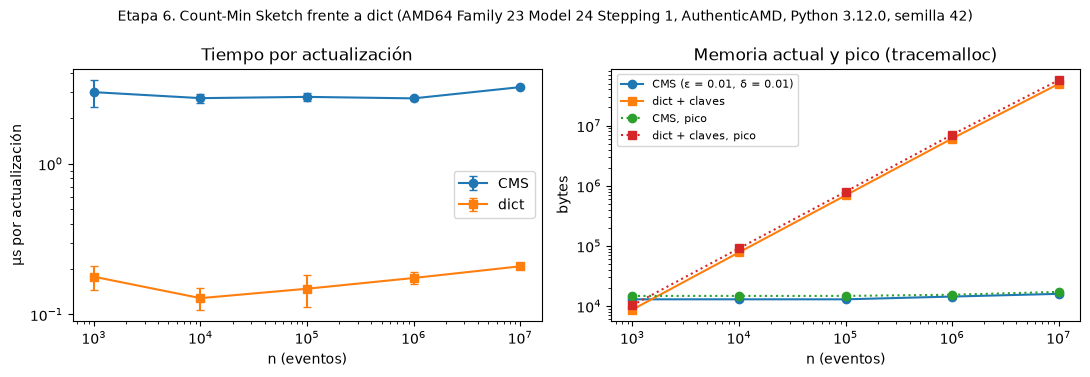

Pendiente log-log del tiempo por actualización (esperada ≈ 0): {'actualizacion_cms_us': 0.01, 'actualizacion_dict_us': 0.03}
Pendiente log-log de la memoria actual (CMS ≈ 0; dict según las claves distintas): {'memoria_cms_bytes': 0.02, 'dict_mas_claves_bytes': 0.94, 'claves_distintas': 0.95}


,n,repeticiones,repeticiones_consulta,claves_distintas,actualizacion_cms_us,actualizacion_cms_std_us,actualizacion_dict_us,consulta_cms_us,consulta_cms_std_us,consulta_dict_us,memoria_cms_bytes,pico_cms_bytes,dict_mas_claves_bytes
0,1000,100,100,98,2.984,0.600,0.178,2.628,0.077,0.059,12944,14745,8740
1,10000,100,100,959,2.723,0.188,0.128,2.818,0.381,0.054,12944,14745,78098
2,100000,100,100,8950,2.776,0.186,0.148,3.022,0.773,0.091,12944,14745,692124
3,1000000,20,100,77262,2.714,0.049,0.175,2.988,0.444,0.218,14384,15419,6102364
4,10000000,1,100,627550,3.222,0.000,0.209,2.920,0.182,0.199,15960,17198,49319828


In [17]:
cms["dict_mas_claves_bytes"] = cms["memoria_dict_bytes"] + cms["memoria_claves_bytes"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.errorbar(cms["n"], cms["actualizacion_cms_us"], yerr=cms["actualizacion_cms_std_us"], marker="o", capsize=3, label="CMS")
ax.errorbar(cms["n"], cms["actualizacion_dict_us"], yerr=cms["actualizacion_dict_std_us"], marker="s", capsize=3, label="dict")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n (eventos)"); ax.set_ylabel("µs por actualización")
ax.set_title("Tiempo por actualización"); ax.legend()
ax = axes[1]
ax.plot(cms["n"], cms["memoria_cms_bytes"], marker="o", label=f"CMS (ε = {EPSILON_EXP}, δ = {DELTA_EXP})")
ax.plot(cms["n"], cms["dict_mas_claves_bytes"], marker="s", label="dict + claves")
ax.plot(cms["n"], cms["pico_cms_bytes"], marker="o", ls=":", label="CMS, pico")
ax.plot(cms["n"], cms["pico_dict_bytes"] + cms["memoria_claves_bytes"], marker="s", ls=":",
        label="dict + claves, pico")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n (eventos)"); ax.set_ylabel("bytes")
ax.set_title("Memoria actual y pico (tracemalloc)"); ax.legend(fontsize=8)
fig.suptitle(f"Etapa 6. Count-Min Sketch frente a dict ({plataforma_de(cms)}, semilla {config.SEED})", fontsize=10)
fig.tight_layout(); fig.savefig(R / "cms_tiempo_memoria.png", dpi=150); plt.show()
print("Pendiente log-log del tiempo por actualización (esperada ≈ 0):",
      {c: round(np.polyfit(np.log10(cms["n"]), np.log10(cms[c]), 1)[0], 2).item()
       for c in ["actualizacion_cms_us", "actualizacion_dict_us"]})
print("Pendiente log-log de la memoria actual (CMS ≈ 0; dict según las claves distintas):",
      {c: round(np.polyfit(np.log10(cms["n"]), np.log10(cms[c]), 1)[0], 2).item()
       for c in ["memoria_cms_bytes", "dict_mas_claves_bytes", "claves_distintas"]})
cms[["n", "repeticiones", "repeticiones_consulta", "claves_distintas", "actualizacion_cms_us",
     "actualizacion_cms_std_us", "actualizacion_dict_us", "consulta_cms_us", "consulta_cms_std_us",
     "consulta_dict_us", "memoria_cms_bytes", "pico_cms_bytes", "dict_mas_claves_bytes"]].round(3)

#### Error de frecuencia

Para cada clave distinta se compara la estimación del CMS con la frecuencia exacta del `dict`. La garantía es error ≤ ε·N con probabilidad 1 − δ, de modo que a lo más un 1 % de las claves puede superar la cota. Como N crece con el stream y la memoria es fija, el error absoluto crece con n.

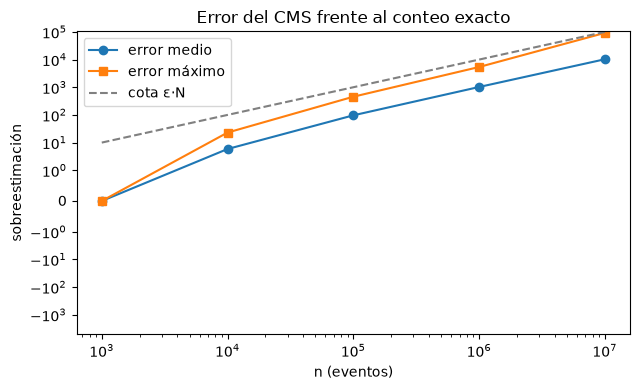

,n,claves_distintas,error_medio,error_max,cota_eps_n,fraccion_sobre_cota,subestimaciones,error_relativo_top10
0,1000,98,0.000000,0,9.993683,0.0,0,0.000000
1,10000,959,5.855057,23,99.936832,0.0,0,0.034257
2,100000,8950,96.555084,454,999.368319,0.0,0,0.044971
3,1000000,77262,1020.831897,5387,9993.683193,0.0,0,0.050603
4,10000000,627550,10267.256504,92031,99936.831929,0.0,0,0.050321


In [18]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(cms["n"], cms["error_medio"], marker="o", label="error medio")
ax.plot(cms["n"], cms["error_max"], marker="s", label="error máximo")
ax.plot(cms["n"], cms["cota_eps_n"], ls="--", color="gray", label="cota ε·N")
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1); ax.set_xlabel("n (eventos)"); ax.set_ylabel("sobreestimación")
ax.set_title("Error del CMS frente al conteo exacto"); ax.legend()
fig.tight_layout(); fig.savefig(R / "cms_error.png", dpi=150); plt.show()
cms[["n", "claves_distintas", "error_medio", "error_max", "cota_eps_n", "fraccion_sobre_cota", "subestimaciones",
     "error_relativo_top10"]]

#### Compromiso memoria-error

El mismo stream de 1M eventos con distintos ε. La memoria crece como 1/ε y el error cae en la misma proporción, así que ε es el parámetro con el que se dimensiona el CMS. En la etapa 6 cada ventana tiene unas decenas de órdenes, por lo que basta ε = 0.01.

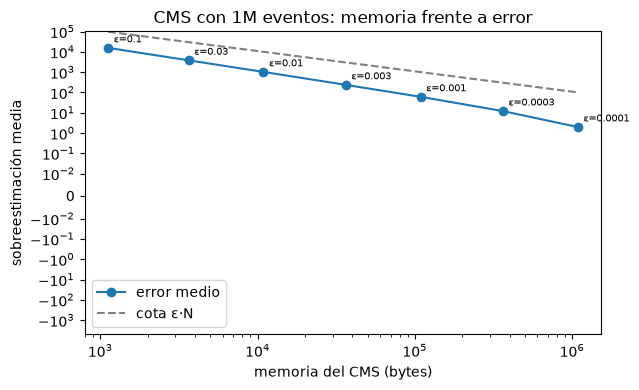

,n,epsilon,w,d,memoria_cms_bytes,error_medio,error_max,subestimaciones,cota_eps_n,fraccion_sobre_cota,error_relativo_top10
0,1000000,0.1000,28,5,1120,15590.248475,66179,0,97081.493874,0.0,0.738576
1,1000000,0.0300,91,5,3640,3795.732851,20829,0,29871.228884,0.0,0.167752
2,1000000,0.0100,272,5,10880,1021.833901,5461,0,9993.683193,0.0,0.050095
3,1000000,0.0030,907,5,36280,235.655072,1003,0,2997.003118,0.0,0.012722
4,1000000,0.0010,2719,5,108760,60.457750,754,0,999.735869,0.0,0.002660
5,1000000,0.0003,9061,5,362440,12.009467,67,0,299.997995,0.0,0.000659
6,1000000,0.0001,27183,5,1087320,1.965319,19,0,99.999332,0.0,0.000115


In [19]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(epsilon["memoria_cms_bytes"], epsilon["error_medio"], marker="o", label="error medio")
ax.plot(epsilon["memoria_cms_bytes"], epsilon["cota_eps_n"], ls="--", color="gray", label="cota ε·N")
for _, f in epsilon.iterrows():
    ax.annotate(f"ε={f['epsilon']:g}", (f["memoria_cms_bytes"], max(f["error_medio"], 1e-3)), fontsize=7,
                textcoords="offset points", xytext=(4, 4))
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=0.01); ax.set_xlabel("memoria del CMS (bytes)")
ax.set_ylabel("sobreestimación media"); ax.set_title("CMS con 1M eventos: memoria frente a error"); ax.legend()
fig.tight_layout(); fig.savefig(R / "cms_epsilon.png", dpi=150); plt.show()
epsilon.drop(columns=["procesador", "python"])

### 8.3 Comparación con una implementación de referencia

La rúbrica pide comparar con implementaciones de referencia. Se usa `pyprobables` (versión 0.7.0), una biblioteca de estructuras probabilísticas en Python puro, para que la comparación sea en el mismo lenguaje. Su Bloom Filter se dimensiona con las mismas fórmulas, así que con n claves y p = 0.01 tiene los mismos m y k que el de la etapa, y calcula sus k posiciones con k hashes FNV-1a de 64 bits con semillas distintas. Su Count-Min Sketch se crea con los mismos w y d que el de la etapa y guarda contadores de 32 bits. Las dos implementaciones reciben los mismos datos de los pasos 8.1 y 8.2.

`pyprobables` calcula FNV-1a carácter por carácter en Python, así que cada operación es mucho más lenta que con BLAKE2b, que está en C. Por eso esta comparación llega hasta 1M, con 100 repeticiones de la construcción hasta 10K, 10 con 100K y una con 1M, y con consultas en 100 bloques de 1 000 claves. La celda imprime cuánto tardaría una sola construcción con 10M.

Resultados leídos de referencia.csv
Bloom Filter de pyprobables con 1M: una construcción tarda 34.5 s; con 10M tardaría unos 345 s
Count-Min Sketch de pyprobables con 1M: una construcción tarda 19.5 s; con 10M tardaría unos 195 s


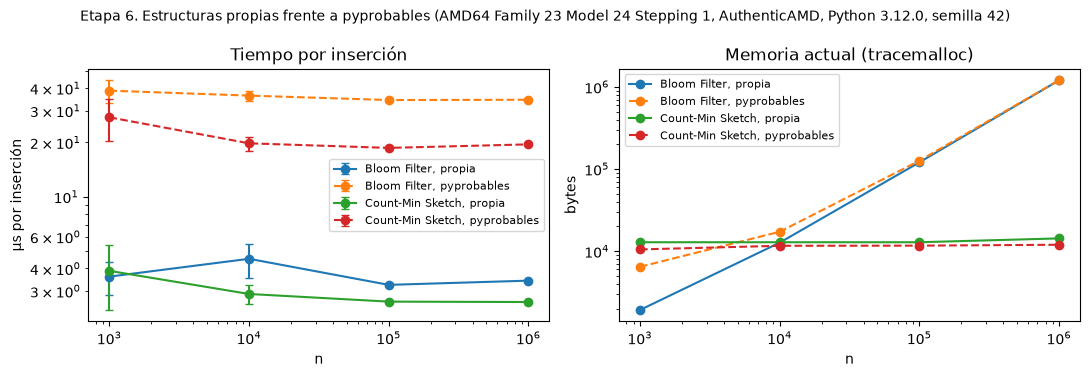

insercion_us  consulta_us  \
estructura       n       implementacion                              
Bloom Filter     1000    propia                3.6031       2.3395   
                         pyprobables          38.7610      39.6110   
Count-Min Sketch 1000    propia                3.8796       3.1404   
                         pyprobables          27.5751      25.5590   
Bloom Filter     10000   propia                4.5246       3.1396   
                         pyprobables          36.3830      38.5529   
Count-Min Sketch 10000   propia                2.8871       3.0647   
                         pyprobables          19.7794      17.4907   
Bloom Filter     100000  propia                3.2436       2.2757   
                         pyprobables          34.3762      32.5888   
Count-Min Sketch 100000  propia                2.6184       2.7135   
                         pyprobables          18.6539      17.2953   
Bloom Filter     1000000 propia                3.4229       2.3406   
                         pyprobables          34.5142      32.5296   
Count-Min Sketch 1000000 propia                2.6049       2.7506   
                         pyprobables          19.5147      18.1179   

                                         memoria_bytes  pico_bytes  tasa_fp  \
estructura       n       implementacion                                       
Bloom Filter     1000    propia                   1928        2810   0.0095   
                         pyprobables              6463        7323   0.0107   
Count-Min Sketch 1000    propia                  12864       14665      NaN   
                         pyprobables             10520       11340      NaN   
Bloom Filter     10000   propia                  12711       13593   0.0098   
                         pyprobables             17246       18106   0.0101   
Count-Min Sketch 10000   propia                  12864       14665      NaN   
                         pyprobables             11648       12596      NaN   
Bloom Filter     100000  propia                 120543      121425   0.0101   
                         pyprobables            126118      127678   0.0100   
Count-Min Sketch 100000  propia                  12864       14665      NaN   
                         pyprobables             11696       13052      NaN   
Bloom Filter     1000000 propia                1200302     1201848   0.0106   
                         pyprobables           1204773     1206369   0.0097   
Count-Min Sketch 1000000 propia                  14328       15507      NaN   
                         pyprobables             11992       13724      NaN   

                                         falsos_negativos  error_medio  \
estructura       n       implementacion                                  
Bloom Filter     1000    propia                       0.0          NaN   
                         pyprobables                  0.0          NaN   
Count-Min Sketch 1000    propia                       NaN       0.0000   
                         pyprobables                  NaN       0.2653   
Bloom Filter     10000   propia                       0.0          NaN   
                         pyprobables                  0.0          NaN   
Count-Min Sketch 10000   propia                       NaN       5.8551   
                         pyprobables                  NaN       6.0563   
Bloom Filter     100000  propia                       0.0          NaN   
                         pyprobables                  0.0          NaN   
Count-Min Sketch 100000  propia                       NaN      96.5551   
                         pyprobables                  NaN      99.5105   
Bloom Filter     1000000 propia                       0.0          NaN   
                         pyprobables                  0.0          NaN   
Count-Min Sketch 1000000 propia                       NaN    1020.8319   
                         pyprobables                  NaN    1053.5011   

                        

In [20]:
from probables import BloomFilter as BloomFilterRef, CountMinSketch as CountMinSketchRef

TAMANOS_REF = [1_000, 10_000, 100_000, 1_000_000]
REPETICIONES_REF = {1_000: 100, 10_000: 100, 100_000: 10, 1_000_000: 1}      # construcciones
N_BLOQUE_REF = 1_000                                                     # consultas por bloque


def experimento_referencia():
    """Bloom Filter y Count-Min Sketch propios frente a los de pyprobables, con los mismos datos y parámetros."""
    filas = []
    for n in TAMANOS_REF:
        reps = REPETICIONES_REF[n]
        insertadas = claves_unicas(n, "pay", config.SEED + n)
        ausentes = claves_unicas(N_CONSULTAS, "aus", config.SEED + n + 1)
        flujo = flujo_zipf(n, config.SEED + n)
        exacto = Counter(flujo)
        w, d = CountMinSketch.para(EPSILON_EXP, DELTA_EXP).w, CountMinSketch.para(EPSILON_EXP, DELTA_EXP).d
        casos = [("Bloom Filter", "propia", lambda: BloomFilter.para(n, P_FP), "agregar", "contiene", insertadas, ausentes),
                 ("Bloom Filter", "pyprobables", lambda: BloomFilterRef(est_elements=n, false_positive_rate=P_FP),
                  "add", "check", insertadas, ausentes),
                 ("Count-Min Sketch", "propia", lambda: CountMinSketch(w, d), "agregar", "estimar", flujo, list(exacto)),
                 ("Count-Min Sketch", "pyprobables", lambda: CountMinSketchRef(width=w, depth=d), "add", "check", flujo,
                  list(exacto))]
        for estructura, implementacion, crear, insertar, consultar, datos, consultas in casos:
            def construir():
                e = crear()
                agregar = getattr(e, insertar)
                for c in datos:
                    agregar(c)
                return e

            e = construir()
            t = medir(construir, reps)
            t_q = medir_bloques(lambda bloque: [getattr(e, consultar)(c) for c in bloque], consultas, N_BLOQUE_REF)
            actual, pico = memoria(construir)
            fila = {"estructura": estructura, "implementacion": implementacion, "n": n, "repeticiones": reps,
                    "insercion_us": statistics.mean(t) / n * 1e6,
                    "insercion_std_us": (statistics.stdev(t) if reps > 1 else 0) / n * 1e6,
                    "consulta_us": statistics.mean(t_q) * 1e6, "consulta_std_us": statistics.stdev(t_q) * 1e6,
                    "memoria_bytes": actual, "pico_bytes": pico}
            if estructura == "Bloom Filter":
                fila["falsos_negativos"] = sum(not getattr(e, consultar)(c) for c in insertadas[:N_CONSULTAS])
                fila["tasa_fp"] = sum(bool(getattr(e, consultar)(c)) for c in ausentes) / N_CONSULTAS
            else:
                errores = np.array([getattr(e, consultar)(c) - f for c, f in exacto.items()], dtype=np.int64)
                fila.update(error_medio=float(errores.mean()), error_max=int(errores.max()),
                            subestimaciones=int((errores < 0).sum()),
                            fraccion_sobre_cota=float((errores > np.e / w * len(flujo)).mean()))
            filas.append(fila)
            del e
        print(f"Implementación de referencia, n = {n:,} medido")
    return pd.DataFrame(filas)


referencia = resultados(R / "referencia.csv", experimento_referencia)
assert referencia["repeticiones"].tolist() == [REPETICIONES_REF[n] for n in TAMANOS_REF for _ in range(4)]
for estructura in ["Bloom Filter", "Count-Min Sketch"]:
    f = referencia[(referencia["estructura"] == estructura) & (referencia["implementacion"] == "pyprobables")
                   & (referencia["n"] == TAMANOS_REF[-1])].iloc[0]
    segundos = f["insercion_us"] * f["n"] / 1e6
    print(f"{estructura} de pyprobables con 1M: una construcción tarda {segundos:.1f} s; con 10M tardaría "
          f"unos {segundos * 10:.0f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for (estructura, implementacion), datos in referencia.groupby(["estructura", "implementacion"], sort=False):
    estilo = "-" if implementacion == "propia" else "--"
    ax1.errorbar(datos["n"], datos["insercion_us"], yerr=datos["insercion_std_us"], ls=estilo, marker="o", capsize=3,
                 label=f"{estructura}, {implementacion}")
    ax2.plot(datos["n"], datos["memoria_bytes"], ls=estilo, marker="o", label=f"{estructura}, {implementacion}")
for ax, titulo, ylabel in [(ax1, "Tiempo por inserción", "µs por inserción"), (ax2, "Memoria actual (tracemalloc)", "bytes")]:
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n"); ax.set_ylabel(ylabel); ax.set_title(titulo)
    ax.legend(fontsize=8)
fig.suptitle(f"Etapa 6. Estructuras propias frente a pyprobables ({plataforma_de(referencia)}, semilla {config.SEED})",
             fontsize=10)
fig.tight_layout(); fig.savefig(R / "referencia.png", dpi=150); plt.show()

columnas = ["insercion_us", "consulta_us", "memoria_bytes", "pico_bytes", "tasa_fp", "falsos_negativos", "error_medio",
            "error_max", "subestimaciones", "fraccion_sobre_cota"]
referencia.set_index(["estructura", "n", "implementacion"])[columnas].dropna(axis=1, how="all").round(4)

### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada, con la plataforma del paso 1. Los conteos y las tasas dependen solo de los datos y de la semilla; los tiempos cambian con la máquina.

- **Paso 2, Bloom Filter de la etapa.** Con las 140 claves conocidas, m = 1 342 bits (168 bytes, 9.59 bits por clave) y k = 7. Quedó encendido el 52.1 % de los bits, cerca de la mitad que deja el k óptimo. De 100 000 tarjetas ausentes, 1 060 dan positivo, una tasa de 1.06 % con un intervalo de 95 % de 1.00 % a 1.12 %, que contiene la tasa teórica (1.00 %) y la esperada para este filtro (1.04 %). Ninguna clave insertada dio negativo. De las 140 claves señaladas que el detector no conoce, 2 dan positivo; la verificación exacta del detector las descarta.
- **Paso 2, doble hashing.** En 200 filtros de 140 claves, el doble hashing da una tasa media de 1.091 % (error estándar de 0.011 %), un 8.9 % más que la esperada (1.002 %) y unos 8 errores estándar por encima. Con hashes independientes la tasa media es 1.017 % (error estándar de 0.010 %), a 1.3 errores estándar de la esperada (1.004 %). Con doble hashing, las k posiciones de una clave son una progresión aritmética módulo m, y con m = 1 342 hay pocos pasos h2 mod m posibles, unos 670. Una clave consultada comparte con frecuencia el paso, o su opuesto, con alguna de las 140 claves insertadas, y entonces sus posiciones son una traslación de las de esa clave y pueden coincidir en varias. Kirsch y Mitzenmacher (2006) prueban que la diferencia desaparece cuando m crece. Como los k valores salen de un solo BLAKE2b, la etapa usa hashes independientes sin calcular más hashes por clave.
- **Paso 3, CMS de una ventana.** Con ε = δ = 0.01, w = 272 y d = 5, cada ventana ocupa 10.6 KB y las 288 ventanas retenidas 3.1 MB. Con 2 000 tarjetas de un intento y una de 7, N = 2 007 y la cota es ε·N = 20.1. Ninguna estimación queda por debajo de la frecuencia real y ninguna supera la cota. La estimación media de las tarjetas de un intento es 5.38, por encima del umbral de 5, y la de la ráfaga es 12. En una ventana así de cargada casi todas las tarjetas llegarían al umbral, y por eso el detector confirma cada alerta del CMS con el conteo exacto de la ventana.
- **Paso 3, doble hashing en el CMS.** En ventanas de 20 tarjetas, el doble hashing sobreestima 92 de 200 000 tarjetas (0.046 %), cerca de las 103 que predice el choque en las 5 filas: como h2 es impar y w = 272 es par, h2 mod w solo toma 136 valores, y dos claves comparten el par (h1 mod w, h2 mod w) con probabilidad 1/(272·136) ≈ 2.7·10⁻⁵. Con filas independientes queda 1 tarjeta sobreestimada, del orden de lo que predice (1 − (271/272)^19)^5 ≈ 1.4·10⁻⁶ por tarjeta.
- **Paso 4, primeros 300 000 eventos.** Hay 62 614 compras y alertas de pago revisadas. La `TablaHash` descarta 1 896 falsos positivos del Bloom Filter, y hay 1 230 bloqueos y 144 órdenes retenidas por ráfaga. En el mismo tramo, con la lista completa, la ejecución de Aris tuvo 1 373 bloqueos y 67 retenciones. Con la mitad de la lista, 143 operaciones dejan de bloquearse: 77 quedan retenidas por la regla de ráfaga y 66 se aprueban.
- **Paso 5, decisiones.** Los 9 940 617 eventos se procesan en 184 s, de los cuales 56 s son del detector (28.1 µs por compra o alerta revisada) y el resto es la lectura del archivo. Del fraude, 41 532 operaciones se bloquean, 3 247 se retienen y 2 987 se aprueban. De las legítimas, ninguna se bloquea y 2 931 se retienen. Los bloqueos tienen precisión 1.000 y recall 0.870, y el conjunto de las alertas tiene precisión 0.939 y recall 0.938. Las órdenes bloqueadas para la etapa 8 son 31 994, y las alertas para la etapa 9 son 47 710 (las 41 532 operaciones bloqueadas y las 6 178 retenidas).
- **Paso 5, aporte de cada estructura.** El fraude con alguna clave conocida, 41 532 operaciones, se bloquea completo. El fraude con sus tres claves nuevas son 6 234 operaciones, el 13.1 % del fraude, cerca del 1/8 esperado. La regla de ráfaga retiene el 52.1 % de esas operaciones y el 47.9 % se aprueba: son las primeras compras de cada ráfaga, antes de que su tarjeta llegue al umbral, y las alertas de pago, que no suman al CMS. Las 2 931 retenciones legítimas son usuarios con 5 o más órdenes con la misma tarjeta en dos ventanas, y la verificación exacta confirma que esas órdenes existen; por eso se retienen en lugar de bloquearse.
- **Paso 5, Bloom Filter en el stream.** De 5 981 862 consultas, 70 860 positivos se confirman en la `TablaHash` y 61 183 son falsos positivos que la verificación descarta; ninguno bloquea una operación. La tasa es de 1.04 % por consulta y de 1.05 % por clave distinta, con 33 116 de 3 162 462 claves no conocidas e intervalo de 95 % de 1.04 % a 1.06 %. Coincide con la tasa esperada para este filtro (1.04 %), que supera la teórica porque el filtro encendió el 52.1 % de sus bits. Cada clave se consulta 1.87 veces en promedio, y la tasa por consulta es igual a la tasa por clave. El 1.08 % por consulta de la ejecución de Aris es coherente con el exceso del doble hashing medido en el paso 2.
- **Paso 5, CMS frente al conteo exacto.** En 1 978 936 compras no hubo subestimaciones. El 0.082 % (1 627 compras) tiene alguna sobreestimación, con un máximo de 2, frente al 0.14 % y un máximo de 15 con doble hashing en la ejecución de Aris. Las sobreestimaciones que quedan corresponden a las ventanas con más órdenes. Con N órdenes en las dos ventanas, la probabilidad de que las 5 filas de una tarjeta choquen es (1 − e^(−N/272))^5, que pasa de 2·10⁻⁶ con 20 órdenes a 4 % con 200. Ningún evento llegó más de 24 h tarde. El CMS ocupa 3.1 MB fijos, frente a los 1 260 275 pares (tarjeta, ventana) del conteo exacto.
- **Paso 6, umbral.** Con umbral 5, la regla de ráfaga sola detecta el 67.6 % de las compras fraudulentas con precisión 0.895. El recall está acotado por el tamaño de las ráfagas, porque las primeras 4 compras de cada una no llegan al umbral. Bajar a 4 o subir a 6 cambia el recall en 8.1 puntos, a cambio de multiplicar por 2.5 o reducir a la mitad las compras legítimas retenidas.
- **Paso 8, repeticiones.** Las consultas tienen 100 bloques de 10 000 claves en todos los tamaños. Las construcciones tienen 100 repeticiones hasta 100K, 20 con 1M y una con 10M. Una construcción del Bloom Filter tarda 3.8 s con 1M y 38.9 s con 10M, y 100 tomarían 6 y 65 min. Una del CMS tarda 2.7 s y 32.2 s, y 100 tomarían 5 y 54 min.
- **Paso 8, Bloom Filter frente a set, tiempo.** El Bloom Filter inserta en 3.4 a 3.9 µs por clave y consulta en 2.4 a 2.6 µs, con pendientes de 0.02 y 0.01: el costo por operación es constante, O(k). El `set` es entre 24 y 52 veces más rápido al insertar y entre 14 y 50 al consultar, porque está escrito en C. Su tiempo por operación crece algo con n, con pendientes de 0.11 y 0.16, porque una tabla grande deja de caber en la caché del procesador.
- **Paso 8, Bloom Filter frente a set, memoria.** El Bloom Filter ocupa 1.20 bytes por clave desde 100K, los 9.6 bits del diseño, y 12.0 MB con 10M. Su pico es igual a la memoria actual, porque el arreglo de bits se reserva una sola vez. El `set` con sus claves ocupa de 88 a 113 bytes por clave y 878 MB con 10M, y el pico de su tabla es 1.5 veces la tabla final por las redimensiones. El Bloom Filter ocupa entre 49 y 89 veces menos. Las pendientes de la memoria son 0.96 y 0.99, como predice O(n).
- **Paso 8, falsos positivos.** La tasa medida va de 0.95 % a 1.06 %, frente al 1.00 % teórico. Con 100 000 consultas el intervalo de 95 % alrededor de la teórica es de ±0.06 puntos, y las cinco mediciones caen dentro. No hubo ningún falso negativo.
- **Paso 8, CMS frente a dict, tiempo.** El CMS actualiza en 2.7 a 3.2 µs y estima en 2.6 a 3.0 µs, con pendiente de 0.01. El `dict` actualiza en 0.13 a 0.21 µs y consulta en 0.05 a 0.22 µs.
- **Paso 8, CMS frente a dict, memoria.** Con ε = δ = 0.01 los contadores ocupan 10 880 bytes, y `tracemalloc` mide de 12.9 a 16.0 KB. La diferencia es el espacio que `array` reserva de más al crear cada fila, 1/16 de su tamaño, más los encabezados de los objetos. Es la misma razón por la que la medición de Aris daba 116 KB para 108 760 bytes de contadores con ε = 0.001. La memoria del CMS sube un 23 % de 1K a 10M (pendiente de 0.02). La del `dict` con sus claves crece con las claves distintas (pendiente de 0.94, frente a 0.95 de las claves distintas) y llega a 49.3 MB con 10M, 3 090 veces la del CMS.
- **Paso 8, error de frecuencia.** No hubo subestimaciones en ningún tamaño, y ninguna clave superó la cota ε·N, frente al δ = 1 % que permite la garantía. El error medio crece con N, porque la memoria es fija: es 5.9 con 10K, 1 021 con 1M y 10 267 con 10M, alrededor del 10 % de la cota desde 100K. El error relativo de las 10 claves más frecuentes es de 3 % a 5 %.
- **Paso 8, compromiso memoria-error.** Con 1M eventos, la memoria crece como 1/ε, de 1.1 KB con ε = 0.1 a 1.1 MB con ε = 0.0001, y el error medio baja de 15 590 a 2.0. El error relativo de las 10 claves más frecuentes pasa de 74 % a 0.01 %. El pipeline usa ε = 0.01 porque cada ventana tiene del orden de 20 órdenes, y entonces ε·N es menor que 1.
- **Paso 8.3, implementación de referencia.** Con los mismos datos y parámetros, el Bloom Filter propio inserta entre 8 y 11 veces más rápido que el de `pyprobables`, con 3.2 a 4.5 µs frente a 34 a 39 µs, y consulta entre 12 y 17 veces más rápido. La diferencia es el hash: el propio calcula un BLAKE2b en C, y `pyprobables` calcula 7 FNV-1a carácter por carácter en Python. Los dos filtros tienen los mismos m y k, ocupan lo mismo desde 100K (1.20 MB con 1M) y tienen la misma tasa de falsos positivos, de 0.95 % a 1.07 %, sin falsos negativos. El Count-Min Sketch propio actualiza unas 7 veces más rápido y estima entre 6 y 8 veces más rápido. Los dos tienen el mismo error, 1 021 y 1 054 en promedio con 1M, sin subestimaciones ni claves sobre la cota. El de `pyprobables` ocupa algo menos, 12.0 KB frente a 14.3 KB con 1M, porque guarda contadores de 32 bits en lugar de 64. Una construcción de `pyprobables` con 1M tarda 34.5 s el Bloom Filter y 19.5 s el CMS, así que con 10M tardaría unos 6 y 3 minutos.

El Bloom Filter y el CMS de la etapa cumplen sus garantías de error con los datos reales. Con la mitad de la lista, el Bloom Filter bloquea todo el fraude que usa alguna clave conocida sin bloquear ninguna operación legítima, porque cada positivo se verifica en la `TablaHash`. La regla de ráfaga del CMS retiene la mitad del fraude con claves nuevas, que es el que el Bloom Filter no puede reconocer. En los experimentos, las dos estructuras tienen un costo constante por operación. El Bloom Filter usa memoria O(n) con 9.6 bits por clave, y el CMS usa memoria fija. Las alternativas exactas en C son más rápidas por un factor constante, pero el `set` ocupa entre 49 y 89 veces más memoria que el Bloom Filter, y el `dict` ocupa 3 090 veces más que el CMS con 10M eventos. Frente a la implementación de referencia `pyprobables`, las estructuras propias son de 6 a 17 veces más rápidas con los mismos errores.

**Referencias.** Bloom, B. H. (1970). Space/time trade-offs in hash coding with allowable errors. *Communications of the ACM*, 13(7), 422-426. Broder, A., y Mitzenmacher, M. (2004). Network applications of Bloom filters: A survey. *Internet Mathematics*, 1(4), 485-509. Chang, F., et al. (2006). Bigtable: A distributed storage system for structured data. *Proceedings of OSDI 2006*, 205-218. Charikar, M., Chen, K., y Farach-Colton, M. (2002). Finding frequent items in data streams. *Proceedings of ICALP 2002*, LNCS 2380, 693-703. Cormode, G., y Muthukrishnan, S. (2005). An improved data stream summary: The Count-Min sketch and its applications. *Journal of Algorithms*, 55(1), 58-75. Estan, C., y Varghese, G. (2002). New directions in traffic measurement and accounting. *Proceedings of ACM SIGCOMM 2002*, 323-336. Fan, L., Cao, P., Almeida, J., y Broder, A. Z. (2000). Summary cache: A scalable wide-area web cache sharing protocol. *IEEE/ACM Transactions on Networking*, 8(3), 281-293. Kirsch, A., y Mitzenmacher, M. (2006). Less hashing, same performance: Building a better Bloom filter. *Proceedings of ESA 2006*, LNCS 4168, 456-467. Leskovec, J., Rajaraman, A., y Ullman, J. D. (2020). *Mining of Massive Datasets* (3.ª ed.), cap. 4. Cambridge University Press.

**Implementaciones de referencia.** `pyprobables` 0.7.0, comparada en el paso 8.3; Google Guava (`com.google.common.hash.BloomFilter`); RedisBloom (comandos `BF.*` y `CMS.*`); Apache Spark (`org.apache.spark.util.sketch.CountMinSketch`).